# Know your study area: the complete guide (Quetta and Balochistan)

One connected notebook for researchers from any discipline who want to understand a place from open data and their own
field material, with Quetta (city) and Balochistan (province) as the worked example. It joins the guide's eight
chapters: first steps, city data, province data, your own field material, overlays and calculations, maps and
interactivity, questions by discipline, and ethics, safety and critical cartography.

Open it in Google Colab and nothing needs installing. Data: © OpenStreetMap contributors (ODbL); Overture Maps
Foundation (CDLA-Permissive 2.0 / ODbL); WorldPop 2020 (CC BY 4.0); OCHA/HDX boundaries (CC BY-IGO) and census 2017
population; UCDP GED 25.1 (CC BY 4.0). Field-data examples are invented.

## <a id="contents"></a>Contents

1. [First steps: maps for people who have never made one](#chapter-00)
2. [Quetta: getting the open data for a city](#chapter-01)
3. [A whole province: Balochistan from open data](#chapter-02)
4. [Your own material: field notes, interviews, routes, sketch maps and many names](#chapter-03)
5. [Overlays and calculations: what is near what, who can reach what, where things cluster](#chapter-04)
6. [Making maps and graphics that tell the truth, and making them interactive](#chapter-05)
7. [Asking your discipline's questions of a place](#chapter-06)
8. [Ethics, safety and critical cartography](#chapter-07)

Run the cells from top to bottom; each chapter uses what the chapters before it made.

# <a id="chapter-00"></a>Chapter 1. First steps: maps for people who have never made one

This guide is for researchers who know a place through people, archives, texts or fieldwork, and want maps to
help them think and argue: ethnographers, historians, sociologists, political scientists, scholars of gender,
labour, religion or literature. If you have never written code, start here. Nothing needs installing.

## Three ways to work, and when to use each

| Route | Good for | Start |
|---|---|---|
| **uMap** or **Felt** in the browser | a quick shareable map of your own places, routes and notes; no code at all | umap.openstreetmap.fr, felt.com |
| **QGIS** on your computer | careful maps for a thesis or book, tracing old maps, editing layers by hand | qgis.org (free) |
| **These notebooks** (Python, in Google Colab) | anything repeated, counted, measured or combined: distances, overlaps, statistics, many districts at once | the "Open in Colab" link on each notebook |

Most people use all three. Sketch in uMap, compute in a notebook, finish the figure in QGIS.

## How a notebook works
A notebook is a page of text and small boxes of code (*cells*). Click a cell and press **Shift + Enter** to run it;
the result appears underneath. Run cells from top to bottom. If something breaks, read the last line of the red
message, fix the cell, and run it again: nothing is damaged.

*Running this in Google Colab?* The next cell installs the few libraries Colab lacks (about a minute). Notebooks
04-07 read files made by 01 and 02: run those first in the same session, or keep the `data` folder on Google Drive.

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx", "overturemaps", "mapclassify", "esda", "libpysal", "folium", "plotly"], check=True)

In [2]:
print("Hello. This cell ran.")
2 + 3

Hello. This cell ran.


5

## The four ideas behind every map

**1. A layer is a table with a shape in each row.** Each row is a thing (a district, a road, an interview place);
columns describe it; one special column holds its shape: a **point**, a **line** or a **polygon**.

In [3]:
import geopandas as gpd
from shapely.geometry import Point, LineString, Polygon
things = gpd.GeoDataFrame({
    "name": ["interview place", "route to market", "neighbourhood"],
    "kind": ["point", "line", "polygon"],
    "note": ["met two teachers here", "walked with A. in March", "where most families moved in the 1990s"]},
    geometry=[Point(67.00, 30.19), LineString([(67.00, 30.19), (67.01, 30.20), (67.02, 30.20)]),
              Polygon([(66.99, 30.18), (67.03, 30.18), (67.03, 30.21), (66.99, 30.21)])], crs=4326)
things

,name,kind,note,geometry
0,interview place,point,met two teachers here,POINT (67 30.19)
1,route to market,line,walked with A. in March,"LINESTRING (67 30.19, 67.01 30.2, 67.02 30.2)"
2,neighbourhood,polygon,where most families moved in the 1990s,"POLYGON ((66.99 30.18, 67.03 30.18, 67.03 30.2..."


**2. Coordinates need a reference system (CRS).** Longitude and latitude in degrees (EPSG:4326) are what GPS and
web maps use. To measure metres you *project* to a flat system, such as UTM zone 42N (EPSG:32642) for most of
Balochistan.

In [4]:
print("length of the route in degrees:", round(things.geometry[1].length, 4), "(meaningless)")
print("length in metres:", round(things.to_crs(32642).geometry[1].length), "m")

length of the route in degrees: 0.0241 (meaningless)
length in metres: 2431 m


**3. Layers combine by place.** "Which interviews fall in which district?" is a *spatial join*; "what is within 1
km?" is a *buffer*. Notebooks 04 and 06 are full of these.

**4. A map is an argument.** What you show, leave out, name and colour makes a claim. Notebook 07 is about doing
that honestly and safely.

## Your first interactive map
Zoom with the mouse wheel, drag to move, hover over a shape to read its note.

In [5]:
things.explore(column="kind", tooltip=["name", "note"], tiles="OpenStreetMap", marker_kwds={"radius": 8}, style_kwds={"weight": 3})

## Words you will meet

| Word | Meaning |
|---|---|
| vector | data made of points, lines, polygons (districts, roads, places) |
| raster | data made of a grid of cells (satellite images, population per 100 m) |
| attribute | a column describing each feature |
| basemap | the background map (streets, satellite) under your layers |
| choropleth | a map colouring areas by a value |
| geocode | turn a place name into coordinates |
| georeference | pin a scanned map or photo onto real coordinates |
| OSM | OpenStreetMap, the free world map made by volunteers |

Next: notebook 01 collects open data for a city (Quetta), notebook 02 for a whole province (Balochistan), and
notebook 03 shows how to bring in your own field material.

[Back to contents](#contents). Next: [Chapter 2. Quetta: getting the open data for a city](#chapter-01).

# <a id="chapter-01"></a>Chapter 2. Quetta: getting the open data for a city

**For:** anyone who needs to understand a place from open data, whatever their discipline: sociology,
anthropology, gender studies, history, literature, labour studies, urban studies, public health. No GIS
background is assumed. The example is **Quetta**, Balochistan; change `PLACE` below to study your own area.

**You will collect:**

| Layer | Source | Licence |
|---|---|---|
| Boundary | OpenStreetMap via Nominatim | ODbL |
| Streets as a network | OpenStreetMap via OSMnx (Overpass) | ODbL |
| Buildings and places, OSM | Geofabrik daily extract of OpenStreetMap | ODbL |
| Buildings | OpenStreetMap, and Overture Maps (which merges OSM, Microsoft and Google footprints) | ODbL / CDLA-Permissive |
| Places people go: schools, clinics, mosques, markets, bus stops, workplaces | OpenStreetMap (Geofabrik extract), and Overture places (Meta, Microsoft) | ODbL / CDLA-Permissive |
| Population per 100 m cell | WorldPop 2020, constrained, UN-adjusted | CC BY 4.0 |

Everything is saved to `data/` the first time, so later notebooks (and re-runs) do not download again.

In [6]:
import os, sys, warnings
from pathlib import Path
if (Path(sys.prefix) / "Library/share/gdal").exists():        # Windows conda: tell GDAL where its settings are, before importing it
    os.environ["GDAL_DATA"] = str(Path(sys.prefix) / "Library/share/gdal")
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

PLACE = "Quetta, Balochistan, Pakistan"
CRS = 32642                    # UTM zone 42N: metres, right for Quetta. Find yours at https://epsg.io
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ox.settings.use_cache = True; ox.settings.cache_folder = str(DATA / "osm_cache")
ox.settings.requests_timeout = 600     # large areas take a while; if the main server is busy, try a mirror:
# ox.settings.overpass_url = "https://overpass.kumi.systems/api"

def cached(name, make):
    """Load data/<name>.gpkg if it exists, otherwise make it, save it and return it."""
    f = DATA / f"{name}.gpkg"
    if f.exists():
        return gpd.read_file(f)
    g = make(); g.to_file(f); return g

## 1. The boundary
Nominatim (OpenStreetMap's place search) returns the administrative area matching the name: here Quetta City
Tehsil. Check what you got: a name can match a district, a city or a neighbourhood.

In [7]:
area = cached("boundary", lambda: ox.geocode_to_gdf(PLACE)[["display_name", "geometry"]])
print(area.display_name.iloc[0]); print(f"{area.to_crs(CRS).area.iloc[0] / 1e6:.0f} km²")
poly = area.geometry.iloc[0]

Quetta City Tehsil, Quetta District, Quetta Division, Balochistan, Pakistan
432 km²


## 2. Streets as a network
A street network is a *graph*: junctions are nodes, street segments are edges. Treating streets this way lets us
ask how far places are *along streets*, not as the crow flies. `network_type="walk"` keeps paths people can walk.

In [8]:
gfile = DATA / "walk.graphml"
G = ox.load_graphml(gfile) if gfile.exists() else ox.graph_from_polygon(poly, network_type="walk")
if not gfile.exists(): ox.save_graphml(G, gfile)
nodes, edges = ox.graph_to_gdfs(G)
print(f"{len(nodes):,} junctions, {len(edges):,} street segments, {edges.to_crs(CRS).length.sum() / 2e3:,.0f} km of walkable street")
edges.highway.astype(str).value_counts().head(8)

18,491 junctions, 48,140 street segments, 2,283 km of walkable street


highway
residential     32036
service          6982
unclassified     2224
tertiary         2100
primary          1844
secondary        1822
trunk             488
track             146
Name: count, dtype: int64

## 3. Buildings, from two sources
OpenStreetMap buildings are traced by volunteers; coverage is uneven across the world. Overture Maps adds
machine-detected footprints (Microsoft, Google) where OSM has none. Comparing them shows where each is complete.

In [9]:
# OpenStreetMap two ways. *Overpass* (what OSMnx uses) queries the live database: ideal for small areas, but its
# public servers are often busy and refuse large requests. A *Geofabrik extract* is a daily snapshot of a whole
# country in one file (Pakistan: about 150 MB), read locally with GDAL: slower to start, but it always works.
import sys, re, urllib.request
PBF = DATA / "pakistan-latest.osm.pbf"
if not PBF.exists():
    urllib.request.urlretrieve("https://download.geofabrik.de/asia/pakistan/pakistan-latest.osm.pbf", PBF)
BBOX = tuple(area.total_bounds)

def osm_layer(layer):
    """One layer of the extract inside the area, with every tag in other_tags spread into its own column."""
    g = gpd.read_file(PBF, layer=layer, bbox=BBOX)
    tags = g.other_tags.fillna("").map(lambda t: dict(re.findall(r'"([^"]+)"=>"([^"]*)"', t)))
    extra = pd.DataFrame(list(tags), index=g.index)
    g = pd.concat([g.drop(columns="other_tags"), extra[[c for c in extra.columns if c not in g.columns]]], axis=1)
    return gpd.GeoDataFrame(g, geometry="geometry", crs=4326).loc[lambda d: d.intersects(poly)]

osm_b = cached("buildings_osm", lambda: osm_layer("multipolygons").loc[lambda d: d.building.notna(),
               lambda d: [c for c in ["osm_id", "osm_way_id", "building", "building:levels", "name", "geometry"] if c in d.columns]])

def overture_buildings():
    """Overture buildings in the bounding box (one query to Overture's public cloud release), clipped to the area."""
    import overturemaps
    t = overturemaps.record_batch_reader("building", tuple(area.total_bounds)).read_all()
    g = gpd.GeoDataFrame.from_arrow(t).set_crs(4326, allow_override=True)
    keep = [c for c in ["id", "height", "num_floors", "class", "geometry"] if c in g.columns]
    g = g[keep]
    g["sources"] = [str(s) for s in t.column("sources").to_pylist()] if "sources" in t.column_names else ""
    return g[g.intersects(poly)]
ov_b = cached("buildings_overture", overture_buildings)
print(f"OSM: {len(osm_b):,} buildings; Overture: {len(ov_b):,}")

OSM: 889 buildings; Overture: 254,056


In [10]:
ov_b["origin"] = np.select([ov_b.sources.str.contains("OpenStreetMap"), ov_b.sources.str.contains("Microsoft"),
                            ov_b.sources.str.contains("Google")], ["OpenStreetMap", "Microsoft ML", "Google Open Buildings"], "other")
ov_b.origin.value_counts()

origin
Google Open Buildings    162968
Microsoft ML              90199
OpenStreetMap               889
Name: count, dtype: int64

## 4. Places people go
Two sources again: OSM tags and Overture's business and venue listings (which come largely from Meta and
Microsoft). Both are sparse in Quetta; together they are a better, still incomplete, picture.

OpenStreetMap tags describe what a place is (`amenity=school`, `shop=*`, `building=mosque`). Pick tags that match
your question; here a general set. Each becomes a point (polygons are reduced to their centre).

In [11]:
COL = lambda p, k: p[k] if k in p.columns else pd.Series(index=p.index, dtype=object)

def places():
    """Points of interest (points, and areas reduced to a point) with a simple category."""
    p = pd.concat([osm_layer("points"), osm_layer("multipolygons")], ignore_index=True)
    am, sh = COL(p, "amenity"), COL(p, "shop")
    p["category"] = np.select(
        [am.isin(["school", "college", "university", "library", "kindergarten", "madrasa"]),
         am.isin(["hospital", "clinic", "doctors", "pharmacy", "dentist"]) | COL(p, "healthcare").notna(),
         am.eq("place_of_worship") | COL(p, "building").isin(["mosque", "church", "temple"]),
         sh.notna() | am.eq("marketplace"),
         COL(p, "highway").eq("bus_stop") | am.eq("bus_station") | COL(p, "public_transport").notna() | COL(p, "railway").eq("station"),
         COL(p, "landuse").eq("industrial") | COL(p, "man_made").eq("works") | COL(p, "office").notna() | COL(p, "craft").notna(),
         COL(p, "leisure").isin(["park", "playground", "sports_centre", "pitch", "stadium"]),
         COL(p, "historic").notna() | COL(p, "tourism").isin(["museum", "attraction"])],
        ["education", "health", "worship", "shops and markets", "public transport", "work", "leisure", "heritage"], "")
    p = p[p.category != ""].copy()
    p["geometry"] = p.geometry.representative_point()
    keep = [c for c in ["osm_id", "name", "name:en", "name:ur", "amenity", "shop", "religion", "category", "geometry"] if c in p.columns]
    return p[keep]
osm_poi = cached("places_osm", places)
osm_poi["source"] = "OpenStreetMap"

def overture_places():
    """Overture places (businesses and venues, mostly from Meta and Microsoft) with the same simple categories."""
    import overturemaps
    t = overturemaps.record_batch_reader("place", tuple(area.total_bounds)).read_all()
    g = gpd.GeoDataFrame.from_arrow(t.select(["id", "geometry", "confidence"])).set_crs(4326, allow_override=True)
    g["name"] = [n["primary"] if n else None for n in t.column("names").to_pylist()]
    g["kind"] = t.column("basic_category").to_pylist()
    k = g.kind.fillna("")
    rules = [("education", "school|college|universit|learning|education|library|tutor"),
             ("health", "hospital|clinic|dental|health|medical|pharmac|diagnostic|doctor|rehabilitation"),
             ("worship", "worship|religious|mosque|church|temple|shrine"),
             ("shops and markets", "store|shop|mall|market|retail|bazaar"),
             ("public transport", "bus|train|station|transport|airport"),
             ("work", "office|service|factory|industr|manufactur|business|construction|law_firm|agency"),
             ("leisure", "park|gym|sport|stadium|fitness|recreation"),
             ("heritage", "historic|museum|monument|landmark")]
    g["category"] = np.select([k.str.contains(p) for _, p in rules], [c for c, _ in rules], "other")
    return g[g.intersects(poly)]
ov_poi = cached("places_overture", overture_places)
ov_poi["source"] = "Overture"
poi = pd.concat([osm_poi, ov_poi[ov_poi.category != "other"]], ignore_index=True)
poi = gpd.GeoDataFrame(poi, geometry="geometry", crs=4326)
poi.to_file(DATA / "places.gpkg")
pd.crosstab(poi.category, poi.source, margins=True)

source,OpenStreetMap,Overture,All
category,,,
education,32,274,306
health,34,121,155
heritage,24,21,45
leisure,48,38,86
public transport,23,49,72
shops and markets,122,296,418
work,56,453,509
worship,28,22,50
All,367,1274,1641


## 5. People: population per 100 m cell
WorldPop estimates how many people live in each 100 m cell, distributing census totals to where buildings are
("constrained"). It is a model, not a count: good for comparing areas, rough for a single street.

In [12]:
import rasterio, rasterio.mask, urllib.request
pop_f = DATA / "population.tif"
if not pop_f.exists():
    url = "https://data.worldpop.org/GIS/Population/Global_2000_2020_Constrained/2020/BSGM/PAK/pak_ppp_2020_UNadj_constrained.tif"
    tmp = DATA / "pak_pop_2020.tif"
    urllib.request.urlretrieve(url, tmp)
    with rasterio.open(tmp) as src:
        arr, tr = rasterio.mask.mask(src, [poly.__geo_interface__], crop=True)
        meta = src.meta | {"height": arr.shape[1], "width": arr.shape[2], "transform": tr, "compress": "deflate"}
    with rasterio.open(pop_f, "w", **meta) as dst:
        dst.write(arr)
    tmp.unlink()
with rasterio.open(pop_f) as src:
    pop = src.read(1, masked=True); pop_tr, pop_crs = src.transform, src.crs
print(f"estimated population in the area: {pop.sum():,.0f}")

estimated population in the area: 646,850


WorldPop puts about 650,000 people in the tehsil. Census-based figures for Quetta city are well above a million.
Constrained models place people only where buildings were detected, and under-count fast-growing and informal
areas, so use these numbers for *relative* comparisons inside the city, and check totals against the census.

## 6. Look at everything together

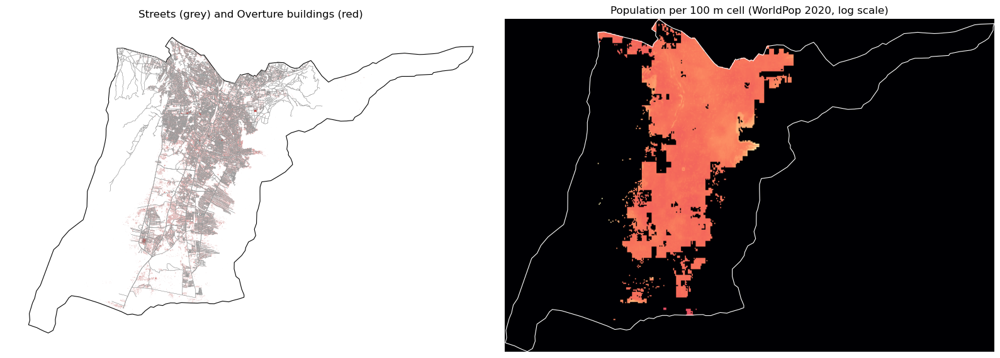

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
area.to_crs(CRS).boundary.plot(ax=ax[0], color="black", lw=.8)
edges.to_crs(CRS).plot(ax=ax[0], color="#999", lw=.3)
ov_b.to_crs(CRS).plot(ax=ax[0], color="#c0504d", lw=0)
ax[0].set_title("Streets (grey) and Overture buildings (red)"); ax[0].set_axis_off()
from rasterio.plot import show
show(np.log1p(pop.filled(0)), transform=pop_tr, ax=ax[1], cmap="magma")
area.boundary.plot(ax=ax[1], color="white", lw=.8)
ax[1].set_title("Population per 100 m cell (WorldPop 2020, log scale)"); ax[1].set_axis_off(); plt.tight_layout()

## 7. An interactive map you can explore
`explore()` turns any layer into a zoomable web map (Leaflet, through folium). Hover for names, click for details,
switch layers on and off at the top right. It works inside Jupyter, Colab and VS Code, and stays interactive in the
saved notebook and in this guide's web page.

In [14]:
import folium
m = area.explore(style_kwds={"fill": False, "color": "black"}, name="boundary", tiles="Esri.WorldGrayCanvas")
colours = {"education": "blue", "health": "red", "worship": "green", "shops and markets": "orange",
           "public transport": "purple", "work": "gray", "leisure": "darkgreen", "heritage": "brown"}
for cat_, col in colours.items():
    sub = poi[poi.category == cat_]
    if len(sub):
        sub.explore(m=m, color=col, name=f"{cat_} ({len(sub)})", tooltip=[c for c in ["name", "category"] if c in sub],
                    marker_kwds={"radius": 4}, show=cat_ in ("education", "health"))
folium.LayerControl(collapsed=False).add_to(m)
m

## What the data can and cannot tell you
- **Coverage is uneven.** An empty patch on the map may mean no buildings or no mappers. Compare sources (section
  3) and look at satellite imagery before concluding.
- **Tags reflect who maps.** Places important to some groups (women's spaces, informal markets, shrines, labour
  camps) are often missing. Absence in OSM is not absence on the ground: fieldwork and local knowledge come first.
- **Population is modelled.** Use it for comparison, not counting individuals.

Next: notebook 02 does the same for the whole province; notebook 04 combines these layers to answer questions: what is near what, who can reach what, where things
cluster.

[Back to contents](#contents). Next: [Chapter 3. A whole province: Balochistan from open data](#chapter-02).

# <a id="chapter-02"></a>Chapter 3. A whole province: Balochistan from open data

Balochistan is Pakistan's largest province by area (about 44% of the country) and its smallest by population. To
study its politics, economy and society you need data at the scale of districts, roads, borders, resources and
events. This notebook gathers them, and is honest about what they leave out.

| Layer | Source | Licence |
|---|---|---|
| Province and district boundaries | OCHA / HDX Common Operational Datasets (COD-AB, 2022) | CC BY-IGO |
| Population by district, census 2017 | HDX COD-PS, from the Pakistan Bureau of Statistics | as published by HDX |
| Roads, settlements, mines and quarries, dams, power, border crossings | OpenStreetMap, Geofabrik extract | ODbL |
| Organised violence events (in Balochistan from 1992) to 2024 | UCDP Georeferenced Event Dataset 25.1 (Uppsala) | CC BY 4.0 |

The 2023 census has published district totals too; swap them in when you need the latest figures (the method does
not change). For protests and political events after 2024, ACLED is the usual source; it needs a free account and
its terms do not allow republishing its rows, so it is shown as code you can run with your own key.

In [15]:
import os, sys, re, warnings, zipfile, urllib.request
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
from pathlib import Path
if (Path(sys.prefix) / "Library/share/gdal").exists():
    os.environ["GDAL_DATA"] = str(Path(sys.prefix) / "Library/share/gdal")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA, CRS = Path("data"), 32642
get = lambda url, f: (DATA / f).exists() or urllib.request.urlretrieve(url, DATA / f)
get("https://data.humdata.org/dataset/a64d1ff2-7158-48c7-887d-6af69ce21906/resource/c6521e04-75e1-41be-8e02-0554a424d9f4/download/pak_admin_boundaries.geojson.zip", "cod_ab.geojson.zip")
get("https://data.humdata.org/dataset/9d48b019-3dd3-4284-ac11-200a70370447/resource/2fe439f1-8c17-4d5b-92d4-909858fc233b/download/pak_admpop_adm2_v2.csv", "pop_adm2.csv")
dist = gpd.read_file("zip://" + str(DATA / "cod_ab.geojson.zip") + "!pak_admin2.geojson")
dist = dist[dist.adm1_name == "Balochistan"][["adm2_name", "adm2_pcode", "area_sqkm", "geometry"]].reset_index(drop=True)
prov = dist.dissolve()
print(len(dist), "districts;", f"{dist.area_sqkm.sum():,.0f} km²")

35 districts; 346,724 km²


## Joining a table to a map, and the trap of changing codes
Census tables and boundary files share a code per district (a *P-code*). But codes and districts change: new
districts are carved out, and code systems are revised. Here the 2019 population file and the 2022 boundaries use
different codes for the same district (Awaran is PK701 in one, PK201 in the other), so we join on names, cleaned,
and list what fails to match.

In [16]:
pop = pd.read_csv(DATA / "pop_adm2.csv", encoding="utf-8-sig")
pop = pop[pop.admin1Name_en == "Balochistan"]
norm = lambda s: s.str.lower().str.replace(r"[^a-z]", "", regex=True)
dist["key"], pop["key"] = norm(dist.adm2_name), norm(pop.admin2Name_en)
pop["key"] = pop.key.replace({"sheerani": "sherani"})          # same district, two spellings (found by the check below)
dist = dist.merge(pop[["key", "T_TL", "U_TL", "R_TL", "M_TL", "F_TL"]].rename(columns={"T_TL": "pop2017", "U_TL": "urban", "R_TL": "rural", "M_TL": "male", "F_TL": "female"}), on="key", how="left")
print("districts without a 2017 population:", dist.loc[dist.pop2017.isna(), "adm2_name"].tolist())
print("population rows without a 2022 district:", sorted(set(pop.key) - set(dist.key)))

districts without a 2017 population: ['Shaheed Sikandarabad', 'Duki', 'Chaman']
population rows without a 2022 district: []


One mismatch was only spelling (Sheerani / Sherani), fixed above. The rest (Duki, Chaman, Shaheed Sikandarabad)
are districts created after 2017. A careful study would either merge new districts
back into their 2017 parents, or use 2023 census figures. Stating the mismatch is part of the method.

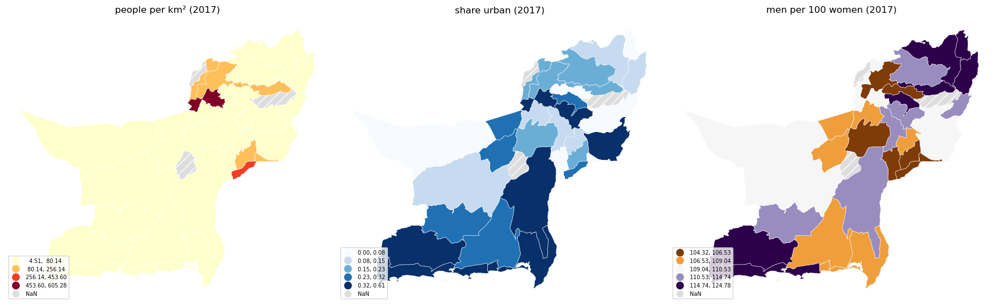

In [17]:
dist["density"] = dist.pop2017 / dist.area_sqkm
dist["urban_share"] = dist.urban / dist.pop2017
dist["sex_ratio"] = dist.male / dist.female * 100
fig, ax = plt.subplots(1, 3, figsize=(18, 7))
for a, (c, cm, t, sch) in zip(ax, [("density", "YlOrRd", "people per km² (2017)", "HeadTailBreaks"), ("urban_share", "Blues", "share urban (2017)", "Quantiles"),
                                    ("sex_ratio", "PuOr", "men per 100 women (2017)", "Quantiles")]):
    dist.plot(c, ax=a, cmap=cm, scheme=sch, k=5, legend=True, missing_kwds={"color": "#ddd", "hatch": "//"},
              legend_kwds={"loc": "lower left", "fontsize": 7, "fmt": "{:.2f}"}, edgecolor="white", lw=.4)
    a.set_title(t); a.set_axis_off()
plt.tight_layout()

In [18]:
dist[["adm2_name", "pop2017", "area_sqkm", "density", "urban_share", "sex_ratio"]].sort_values("pop2017", ascending=False).round(2).head(12)

,adm2_name,pop2017,area_sqkm,density,urban_share,sex_ratio
25,Quetta,2275699.0,3759.73,605.28,0.44,110.37
10,Kech,909116.0,24419.27,37.23,0.33,119.24
12,Khuzdar,802207.0,30954.90,25.92,0.35,110.59
13,Killa Abdullah,757578.0,2992.96,253.12,0.20,110.45
24,Pishin,736481.0,6085.88,121.01,0.19,106.09
16,Lasbela,574292.0,14057.35,40.85,0.49,108.84
6,Jaffarabad,513813.0,1701.84,301.92,0.31,104.32
21,Nasirabad,490538.0,3224.90,152.11,0.20,106.41
9,Kalat,412232.0,10179.77,40.50,0.18,105.56
18,Loralai,397400.0,3796.60,104.67,0.16,114.87


## Infrastructure and resources from OpenStreetMap
The Geofabrik extract of Pakistan (downloaded in notebook 01) holds every OSM feature. We read the province's
roads, places, mines, quarries, dams, power lines and border crossings.

In [19]:
PBF = DATA / "pakistan-latest.osm.pbf"
if not PBF.exists():
    urllib.request.urlretrieve("https://download.geofabrik.de/asia/pakistan/pakistan-latest.osm.pbf", PBF)
poly = prov.geometry.iloc[0]
def osm(layer, where):
    """Features of one layer in the province (GDAL SQL filter on the extract), with other_tags spread into columns."""
    g = gpd.read_file(PBF, layer=layer, bbox=tuple(prov.total_bounds), where=where)
    if "other_tags" in g:
        t = pd.DataFrame(list(g.other_tags.fillna("").map(lambda s: dict(re.findall(r'"([^"]+)"=>"([^"]*)"', s)))), index=g.index)
        g = pd.concat([g.drop(columns="other_tags"), t[[c for c in t.columns if c not in g.columns]]], axis=1)
    return gpd.GeoDataFrame(g, geometry="geometry", crs=4326).loc[lambda d: d.intersects(poly)]

def cached(name, make):
    """Read data/<name>.gpkg or make and save it."""
    f = DATA / f"{name}.gpkg"
    if f.exists(): return gpd.read_file(f)
    g = make(); g.to_file(f); return g

roads = cached("bal_roads", lambda: osm("lines", "highway IN ('motorway','trunk','primary','secondary')")[["name", "highway", "ref", "geometry"]])
places = cached("bal_places", lambda: osm("points", "place IN ('city','town','village')")[["name", "place", "geometry"]])
extract = cached("bal_extraction", lambda: pd.concat([
    osm("multipolygons", "landuse IN ('quarry','industrial') OR man_made IN ('mineshaft','works','petroleum_well')"),
    osm("points", "man_made IN ('mineshaft','adit','petroleum_well','works')")], ignore_index=True).assign(
        geometry=lambda d: d.geometry.representative_point())[["name", "landuse", "man_made", "geometry"]])
border = cached("bal_border", lambda: osm("points", "barrier = 'border_control'")[["name", "geometry"]])
print(f"main roads {roads.to_crs(CRS).length.sum() / 1e3:,.0f} km; towns and villages {len(places):,}; "
      f"mines, quarries, wells and works {len(extract):,}; border crossings {len(border)}")
roads.highway.value_counts()

main roads 9,438 km; towns and villages 1,545; mines, quarries, wells and works 275; border crossings 11


highway
trunk        1136
secondary     911
primary       518
Name: count, dtype: int64

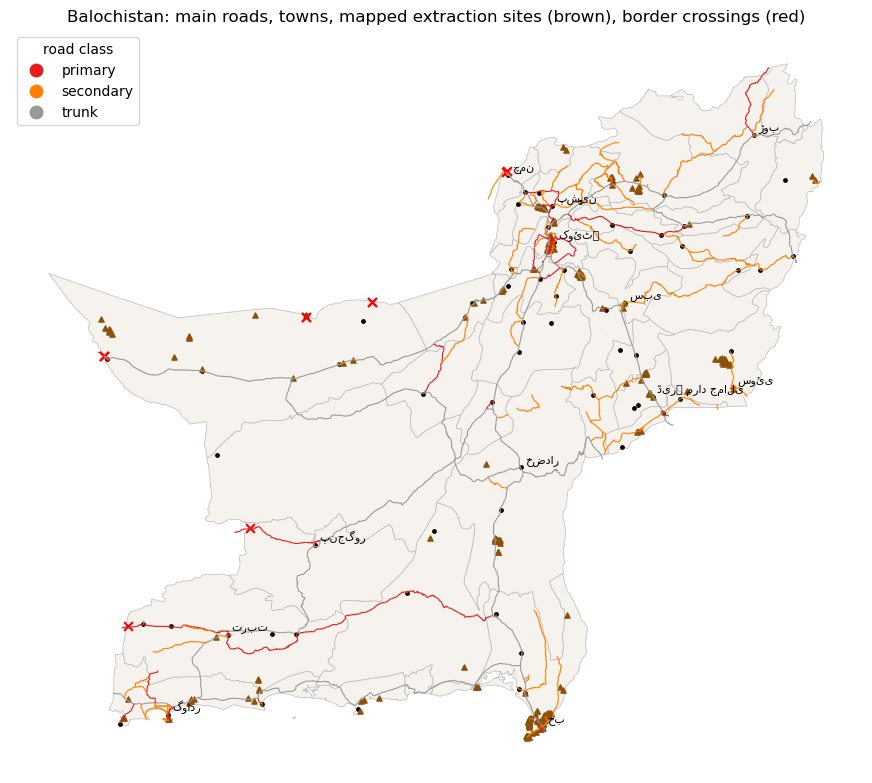

In [20]:
fig, ax = plt.subplots(figsize=(11, 11))
dist.plot(ax=ax, color="#f6f3ee", edgecolor="#bbb", lw=.5)
roads.plot(ax=ax, column="highway", categorical=True, lw=.8, legend=True, cmap="Set1", legend_kwds={"loc": "upper left", "title": "road class"})
places[places.place.isin(["city", "town"])].plot(ax=ax, color="black", markersize=6)
extract.plot(ax=ax, color="#8c510a", marker="^", markersize=14)
border.plot(ax=ax, color="red", marker="x", markersize=40)
for _, r in places[places.place == "city"].iterrows():
    ax.annotate(r["name"], (r.geometry.x, r.geometry.y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_title("Balochistan: main roads, towns, mapped extraction sites (brown), border crossings (red)"); ax.set_axis_off();

## Events through time: UCDP organised violence
UCDP records each event of organised violence with at least one death that it can verify from news and NGO
reports: who against whom, where (with a precision code), when, and best, low and high death estimates. It is a
careful, conservative source: it misses unreported events, and enforced disappearances, arrests and protests are
not in it at all.

In [21]:
ev_f = DATA / "ucdp_balochistan.csv"
if not ev_f.exists():
    z = DATA / "ged.zip"; urllib.request.urlretrieve("https://ucdp.uu.se/downloads/ged/ged251-csv.zip", z)
    g = pd.read_csv(zipfile.ZipFile(z).open(zipfile.ZipFile(z).namelist()[0]), low_memory=False)
    g[(g.country == "Pakistan") & g.adm_1.str.contains("Baluch|Baloch", na=False)].to_csv(ev_f, index=False); z.unlink()
ev = pd.read_csv(ev_f)
ev = gpd.GeoDataFrame(ev, geometry=gpd.points_from_xy(ev.longitude, ev.latitude), crs=4326)
ev["kind"] = ev.type_of_violence.map({1: "state-based", 2: "non-state", 3: "one-sided (against civilians)"})
print(len(ev), "events,", ev.year.min(), "-", ev.year.max(), "; best estimate of deaths:", int(ev.best.sum()))
print("location precision (1 = exact place ... 6+ = province or country):"); print(ev.where_prec.value_counts().sort_index())

1099 events, 1992 - 2024 ; best estimate of deaths: 4251
location precision (1 = exact place ... 6+ = province or country):
where_prec
1    415
2    374
3    267
4     28
5     15
Name: count, dtype: int64


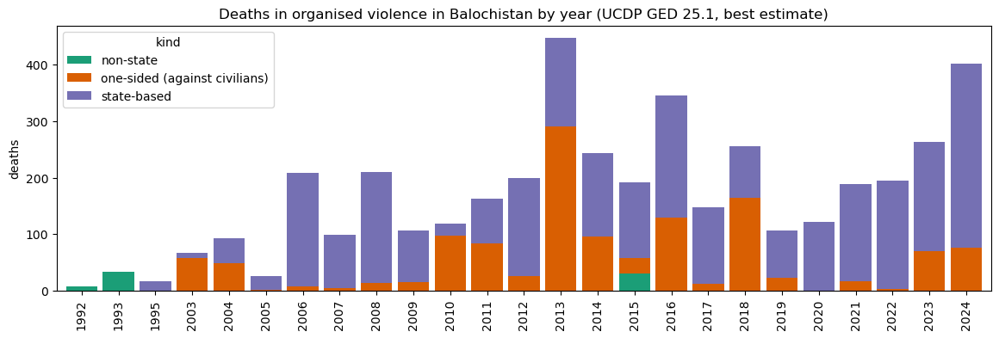

In [22]:
y = ev.groupby(["year", "kind"]).best.sum().unstack(fill_value=0)
ax = y.plot.bar(stacked=True, figsize=(14, 4), width=.85, color=["#1b9e77", "#d95f02", "#7570b3"])
ax.set(title="Deaths in organised violence in Balochistan by year (UCDP GED 25.1, best estimate)", xlabel="", ylabel="deaths");

In [23]:
ev.groupby("side_b").agg(events=("id", "size"), deaths=("best", "sum")).sort_values("events", ascending=False).head(10)

,events,deaths
side_b,,
BRAS,409,801
BLA,193,548
Civilians,151,1260
BRA,148,380
TTP,96,447
IS,32,264
BLF,17,105
UBA,14,118
Baloch Ittehad,9,157


**Reading the actors:** in state-based events side A is the Government of Pakistan and side B the armed group
(BLA, BLF, BRA, BRAS and others, as UCDP names them); one-sided violence is violence by an organised group against
civilians. These are UCDP's categories, not neutral facts: who is called what is political (notebook 07).

## Joining events to districts: rates, not dots

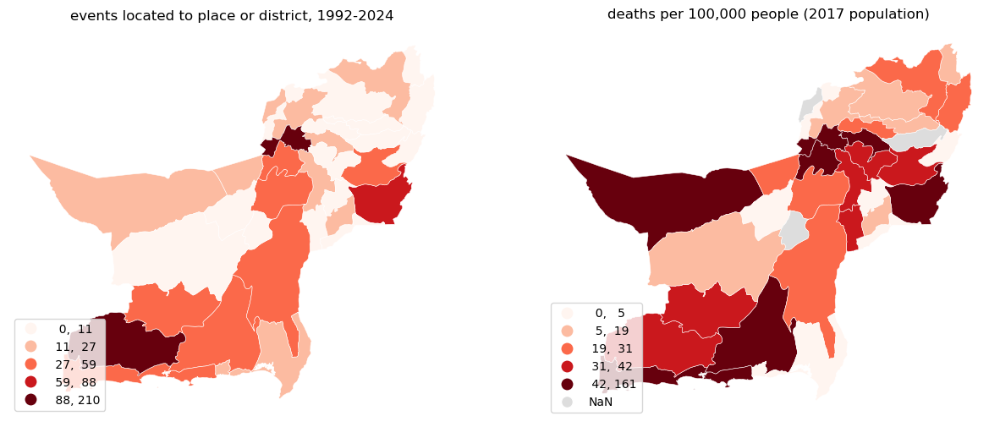

In [24]:
j = gpd.sjoin(ev[ev.where_prec <= 3], dist[["adm2_name", "geometry"]], predicate="within")
k = j.groupby("adm2_name").agg(events=("id", "size"), deaths=("best", "sum"))
dist = dist.merge(k, on="adm2_name", how="left").fillna({"events": 0, "deaths": 0})
dist["deaths_per_100k"] = dist.deaths / dist.pop2017 * 1e5
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
dist.plot("events", ax=ax[0], cmap="Reds", scheme="NaturalBreaks", k=5, legend=True, edgecolor="white", lw=.4, legend_kwds={"loc": "lower left", "fmt": "{:.0f}"})
dist.plot("deaths_per_100k", ax=ax[1], cmap="Reds", scheme="Quantiles", k=5, legend=True, edgecolor="white", lw=.4, missing_kwds={"color": "#ddd"}, legend_kwds={"loc": "lower left", "fmt": "{:.0f}"})
ax[0].set_title(f"events located to place or district, {ev.year.min()}-{ev.year.max()}"); ax[1].set_title("deaths per 100,000 people (2017 population)")
for a in ax: a.set_axis_off()

## An interactive map with a time slider
Drag the slider (or press play) to watch events appear year by year.

In [25]:
import folium
from folium.plugins import TimestampedGeoJson
m = folium.Map(location=[28.5, 65.5], zoom_start=6, tiles="Esri.WorldGrayCanvas")
folium.GeoJson(dist[["adm2_name", "pop2017", "events", "geometry"]].to_json(), name="districts",
               style_function=lambda f: {"fillOpacity": 0, "color": "#666", "weight": .6},
               tooltip=folium.GeoJsonTooltip(["adm2_name", "pop2017", "events"])).add_to(m)
col = {"state-based": "#1b9e77", "non-state": "#d95f02", "one-sided (against civilians)": "#7570b3"}
feats = [{"type": "Feature", "geometry": {"type": "Point", "coordinates": [r.longitude, r.latitude]},
          "properties": {"time": f"{int(r.year)}-01-01", "popup": f"{r.date_start[:10]}: {r.dyad_name}, {int(r.best)} deaths",
                         "icon": "circle", "iconstyle": {"color": col[r.kind], "fillColor": col[r.kind], "fillOpacity": .6, "radius": 3 + min(r.best, 30) ** .5}}}
         for r in ev[ev.where_prec <= 3].itertuples()]
TimestampedGeoJson({"type": "FeatureCollection", "features": feats}, period="P1Y", duration="P3Y", add_last_point=False,
                   auto_play=False, loop=False, date_options="YYYY", time_slider_drag_update=True).add_to(m)
m

## ACLED: protests and political events (needs your own free key)
ACLED codes protests, riots, strategic developments and violence weekly. Register at acleddata.com, then run with
your key in environment variables (never paste a key into a notebook you share). Its terms let you analyse and
publish maps and statistics, not redistribute the rows.

```python
import os, requests
r = requests.get("https://api.acleddata.com/acled/read", params={
    "key": os.environ["ACLED_KEY"], "email": os.environ["ACLED_EMAIL"],
    "country": "Pakistan", "admin1": "Balochistan", "limit": 0})
acled = pd.DataFrame(r.json()["data"])
acled.event_type.value_counts()      # Protests, Riots, Battles, Violence against civilians, ...
```

## Save for later notebooks

In [26]:
dist.drop(columns="key").to_file(DATA / "bal_districts.gpkg")
ev.to_file(DATA / "bal_events.gpkg")
print("saved")

saved


**Credits:** boundaries OCHA/HDX COD-AB (CC BY-IGO); population HDX COD-PS from the Pakistan Bureau of Statistics
census 2017; © OpenStreetMap contributors (ODbL); UCDP GED 25.1 (Sundberg and Melander 2013; Davies et al. 2025),
CC BY 4.0.

[Back to contents](#contents). Next: [Chapter 4. Your own material: field notes, interviews, routes, sketch maps and many names](#chapter-03).

# <a id="chapter-03"></a>Chapter 4. Your own material: field notes, interviews, routes, sketch maps and many names

For an ethnographer or historian the most important data are not online: they are notes, interviews, walks,
photographs, hand-drawn maps and old documents. This notebook shows how to turn them into layers, keeping the
vagueness and multiplicity that real places have, and keeping people safe.

**All examples below are made up** for teaching. Never put real informants' details in a notebook that leaves your
computer (notebook 07).

In [27]:
import warnings; warnings.filterwarnings("ignore")
import io
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from shapely.geometry import Point, LineString
DATA, CRS = Path("data"), 32642

## 1. A spreadsheet of field notes becomes a layer
Keep a simple table while in the field: one row per observation, with what you know about *where*: coordinates
from a phone, or a place name, and how sure you are. Save it as CSV from Excel or Google Sheets.

In [28]:
notes_csv = """id,date,place_name,lat,lon,certainty,theme,note
1,2024-03-02,Liaquat Bazaar,,,named place,work,shopkeepers describe credit from wholesalers
2,2024-03-03,,30.2105,67.0182,GPS,mobility,women's van stop moved after road widening
3,2024-03-05,Hazara Town,,,neighbourhood,security,checkpoints described as daily routine
4,2024-03-09,,30.1748,66.9931,GPS,religion,new madrasa on former orchard land
5,2024-03-11,Quetta Railway Station,,,named place,work,porters' union meeting
6,2024-03-15,Kuchlak,,,town (approx.),migration,families from Afghanistan since the 1980s
"""
notes = pd.read_csv(io.StringIO(notes_csv))
notes

,id,date,place_name,lat,lon,certainty,theme,note
0,1,2024-03-02,Liaquat Bazaar,NaN,NaN,named place,work,shopkeepers describe credit from wholesalers
1,2,2024-03-03,NaN,30.2105,67.0182,GPS,mobility,women's van stop moved after road widening
2,3,2024-03-05,Hazara Town,NaN,NaN,neighbourhood,security,checkpoints described as daily routine
3,4,2024-03-09,NaN,30.1748,66.9931,GPS,religion,new madrasa on former orchard land
4,5,2024-03-11,Quetta Railway Station,NaN,NaN,named place,work,porters' union meeting
5,6,2024-03-15,Kuchlak,NaN,NaN,town (approx.),migration,families from Afghanistan since the 1980s


## 2. Geocoding names, and recording how good each location is
Rows without coordinates are looked up by name (OpenStreetMap's Nominatim). Every location keeps a *certainty*:
a GPS point, a named place, a neighbourhood, a town. Maps should show this, not hide it.

In [29]:
import osmnx as ox, time
for i, r in notes[notes.lat.isna()].iterrows():
    try:
        notes.loc[i, ["lat", "lon"]] = ox.geocode(f"{r.place_name}, Quetta District, Pakistan")
        notes.loc[i, "geocoded"] = "Nominatim"
    except Exception:
        notes.loc[i, "geocoded"] = "not found"
    time.sleep(1)                                   # Nominatim's rule: at most one request per second
notes["geocoded"] = notes.geocoded.fillna("GPS")
g = gpd.GeoDataFrame(notes.dropna(subset=["lat"]), geometry=gpd.points_from_xy(notes.dropna(subset=["lat"]).lon, notes.dropna(subset=["lat"]).lat), crs=4326)
g[["id", "place_name", "certainty", "geocoded", "theme"]]

,id,place_name,certainty,geocoded,theme
1,2,NaN,GPS,GPS,mobility
2,3,Hazara Town,neighbourhood,Nominatim,security
3,4,NaN,GPS,GPS,religion
4,5,Quetta Railway Station,named place,Nominatim,work
5,6,Kuchlak,town (approx.),Nominatim,migration


Uncertainty as a circle: a GPS point is a few metres, a named place a few hundred, a neighbourhood a kilometre,
a town several. Drawing the circle stops readers taking a vague place as an exact one.

In [30]:
radius = {"GPS": 20, "named place": 250, "neighbourhood": 1000, "town (approx.)": 3000}
gu = g.to_crs(CRS); gu["geometry"] = gu.buffer(gu.certainty.map(radius))
m = gu.to_crs(4326).explore(column="theme", tooltip=["date", "place_name", "certainty", "note"], tiles="Esri.WorldGrayCanvas", style_kwds={"fillOpacity": .25})
g.explore(m=m, color="black", marker_kwds={"radius": 2}, tooltip=False)
m

## 3. A walk or a journey becomes a line
From a phone's GPS track (export GPX from apps such as OsmAnd or OpenTracks), or from places in the order someone
described them. Read a GPX file with `gpd.read_file("walk.gpx", layer="tracks")`. Here a described journey:

In [31]:
journey = [("home", 67.0050, 30.1650), ("van stop", 67.0182, 30.2105), ("bazaar", 67.0080, 30.1950), ("clinic", 67.0250, 30.1900)]
route = gpd.GeoDataFrame({"who": ["respondent B (pseudonym)"], "described": ["daily route, as told in interview 7"]},
                         geometry=[LineString([(x, y) for _, x, y in journey])], crs=4326)
stops = gpd.GeoDataFrame({"stop": [s for s, *_ in journey], "order": range(1, 5)}, geometry=[Point(x, y) for _, x, y in journey], crs=4326)
print(f"route length: {route.to_crs(CRS).length.iloc[0] / 1000:.1f} km as the crow flies between stops")
m = route.explore(color="crimson", style_kwds={"weight": 4}, tiles="Esri.WorldGrayCanvas", tooltip=["who", "described"])
stops.explore(m=m, color="crimson", tooltip=["order", "stop"], marker_kwds={"radius": 6}); m

route length: 8.9 km as the crow flies between stops


## 4. Many names for one place
Places in Balochistan carry Balochi, Brahui, Pashto, Hazaragi, Urdu, Persian and English (colonial) names, and
renamings mark political change. Keep them all in a *gazetteer*: one row per place, one column per name and source.

In [32]:
gaz = pd.DataFrame([
    {"place_id": "P1", "name_official": "Quetta", "name_pashto": "کوټه (Kwaṭa)", "name_balochi": "کوئٹہ", "name_colonial": "Quetta", "note": "from Pashto kwaṭ, 'fort'"},
    {"place_id": "P2", "name_official": "Liaquat Bazaar", "name_pashto": "", "name_balochi": "", "name_colonial": "", "note": "named after Pakistan's first prime minister"},
    {"place_id": "P3", "name_official": "Hanna Lake", "name_pashto": "", "name_balochi": "", "name_colonial": "", "note": "reservoir built 1894"},
])
gaz

,place_id,name_official,name_pashto,name_balochi,name_colonial,note
0,P1,Quetta,کوټه (Kwaṭa),کوئٹہ,Quetta,"from Pashto kwaṭ, 'fort'"
1,P2,Liaquat Bazaar,,,,named after Pakistan's first prime minister
2,P3,Hanna Lake,,,,reservoir built 1894


OpenStreetMap often holds several names already (`name`, `name:ur`, `name:ps`, `name:bal`, `old_name`): see
notebook 01's places layer. Which name you print on a map is a choice (notebook 07).

## 5. A sketch map or an old map, placed on today's map (georeferencing)
A drawing by a respondent, a colonial survey sheet or a photograph of a map can be pinned to real coordinates by
matching a few points you can recognise on both (a junction, a mosque, a bridge). QGIS's *Georeferencer* does this
by clicking; in code, `rasterio` fits the transform from your control points:

```python
import rasterio
from rasterio.control import GroundControlPoint as GCP
from rasterio.transform import from_gcps
gcps = [GCP(row=120, col=80,  x=67.0035, y=30.1952),     # pixel on the scan -> lon, lat on today's map
        GCP(row=640, col=95,  x=67.0040, y=30.1801),
        GCP(row=410, col=900, x=67.0280, y=30.1870)]
with rasterio.open("sketch.png") as s:
    prof = s.profile | {"driver": "GTiff", "crs": "EPSG:4326", "transform": from_gcps(gcps)}
    with rasterio.open("sketch_georef.tif", "w", **prof) as d: d.write(s.read())
```
Then overlay it with `folium.raster_layers.ImageOverlay` or in QGIS, and trace what matters as new layers. Old maps
for the region: the Survey of India sheets (some on the David Rumsey Map Collection and in the British Library),
and colonial gazetteers such as the *Baluchistan District Gazetteer Series* (1906-07), which also hold lists of
names, tribes and settlements.

## 6. Participatory mapping
People mark their own places: where they feel safe or watched, where they work, pray, shop, were displaced from.
Use a printed map and stickers, or a shared uMap layer, then enter the marks as in section 1, with consent and with
the precision the participants agree to (notebook 07). Compare whose places appear on official maps and whose do not.

## 7. From qualitative codes to a map
If you code transcripts (in NVivo, Atlas.ti, Taguette or by hand), export a table of *code x place* and join it to
your gazetteer: where does a theme come up, and where does it not?

In [33]:
codes = pd.DataFrame({"place_name": ["Liaquat Bazaar", "Hazara Town", "Kuchlak", "Liaquat Bazaar", "Hazara Town"],
                      "code": ["debt", "checkpoints", "displacement", "checkpoints", "displacement"], "mentions": [5, 9, 7, 2, 3]})
tab = codes.pivot_table(index="place_name", columns="code", values="mentions", fill_value=0)
tab

code,checkpoints,debt,displacement
place_name,,,
Hazara Town,9.0,0.0,3.0
Kuchlak,0.0,0.0,7.0
Liaquat Bazaar,2.0,5.0,0.0


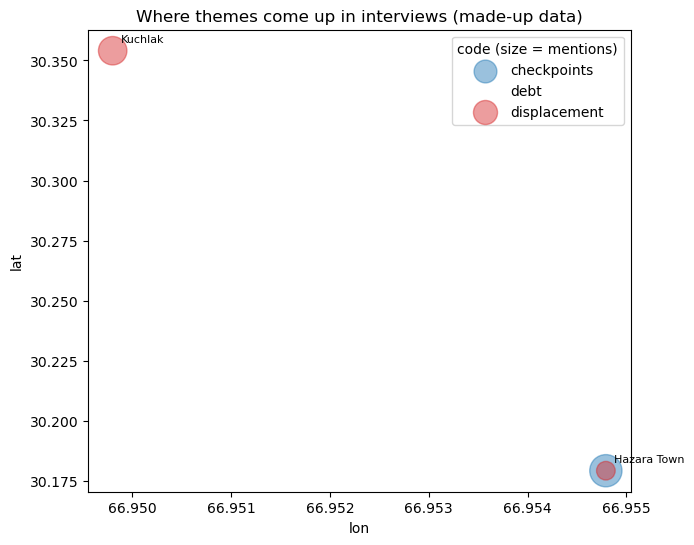

In [34]:
pts = g.dropna(subset=["place_name"]).drop_duplicates("place_name").set_index("place_name").reindex(tab.index).dropna(subset=["lat"])
fig, ax = plt.subplots(figsize=(7, 6))
for k, c in zip(tab.columns, ["C0", "C1", "C3"]):
    s = tab.loc[pts.index, k]
    ax.scatter(pts.lon, pts.lat, s=s * 60, alpha=.45, color=c, label=k)
for n, r in pts.iterrows():
    ax.annotate(n, (r.lon, r.lat), fontsize=8, xytext=(6, 6), textcoords="offset points")
ax.legend(title="code (size = mentions)"); ax.set_title("Where themes come up in interviews (made-up data)"); ax.set_xlabel("lon"); ax.set_ylabel("lat");

[Back to contents](#contents). Next: [Chapter 5. Overlays and calculations: what is near what, who can reach what, where things cluster](#chapter-04).

# <a id="chapter-04"></a>Chapter 5. Overlays and calculations: what is near what, who can reach what, where things cluster

Every spatial question is built from a few operations. This notebook does each one on Quetta's data from
notebook 01, with the question it answers.

| Operation | Question it answers |
|---|---|
| buffer | what lies within 500 m of a school? |
| spatial join, point in polygon | how many clinics are in each part of the city? |
| grid aggregation | where are buildings and people densest? |
| raster to zones (zonal statistics) | how many people live in each cell or area? |
| network distance, isochrones | who can walk to a clinic in 15 minutes? |
| nearest neighbour | how far is each home from the nearest school? |
| kernel density | where do shops concentrate? |
| spatial autocorrelation, hot spots | is that clustering more than chance? |

In [35]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, osmnx as ox, networkx as nx
import matplotlib.pyplot as plt, rasterio
from rasterio.features import geometry_mask
from shapely.geometry import box
DATA, CRS = Path("data"), 32642
area = gpd.read_file(DATA / "boundary.gpkg").to_crs(CRS)
bld = gpd.read_file(DATA / "buildings_overture.gpkg").to_crs(CRS)
poi = gpd.read_file(DATA / "places.gpkg").to_crs(CRS)
G = ox.load_graphml(DATA / "walk.graphml")
print(len(bld), "buildings,", len(poi), "places")

254056 buildings, 1641 places


## 1. A grid to compare like with like
Administrative areas differ in size and shape; a regular grid of 500 m cells makes counts comparable.

In [36]:
S = 500
x0, y0, x1, y1 = area.total_bounds
cells = [box(x, y, x + S, y + S) for x in np.arange(x0, x1, S) for y in np.arange(y0, y1, S)]
grid = gpd.GeoDataFrame(geometry=cells, crs=CRS)
grid = grid[grid.intersects(area.geometry.iloc[0])].reset_index(drop=True); grid["cell"] = grid.index
print(len(grid), "cells of 500 m")

1890 cells of 500 m


## 2. Spatial join: buildings and built-up area per cell

In [37]:
b = bld[["geometry"]].copy(); b["footprint_m2"] = b.area
b["geometry"] = b.representative_point()
j = gpd.sjoin(b, grid, predicate="within").groupby("cell").agg(buildings=("footprint_m2", "size"), built_m2=("footprint_m2", "sum"))
grid = grid.join(j).fillna({"buildings": 0, "built_m2": 0})
grid["built_share"] = grid.built_m2 / S**2
grid.describe().loc[["mean", "50%", "max"], ["buildings", "built_share"]].round(3)

,buildings,built_share
mean,134.421,0.065
50%,1.500,0.000
max,1174.000,0.696


## 3. Zonal statistics: people per cell from the population raster

people in grid: 646,850


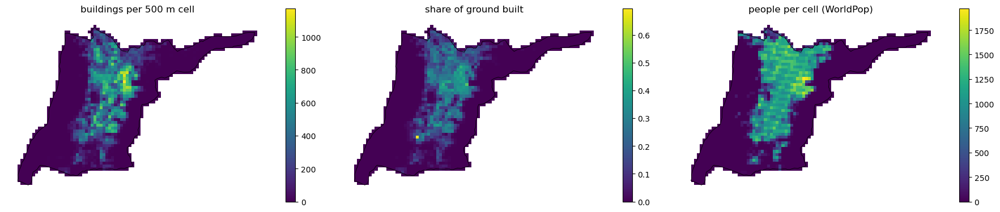

In [38]:
with rasterio.open(DATA / "population.tif") as src:
    pop = src.read(1, masked=True).filled(0); tr, pcrs = src.transform, src.crs
g4 = grid.to_crs(pcrs)
grid["people"] = [pop[~geometry_mask([geom], pop.shape, tr, all_touched=False)].sum() for geom in g4.geometry]
grid["people_per_building"] = grid.people / grid.buildings.replace(0, np.nan)
print(f"people in grid: {grid.people.sum():,.0f}")
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, (col, t) in zip(ax, [("buildings", "buildings per 500 m cell"), ("built_share", "share of ground built"), ("people", "people per cell (WorldPop)")]):
    grid.plot(col, ax=a, cmap="viridis", legend=True, legend_kwds={"shrink": .6}); area.boundary.plot(ax=a, color="k", lw=.6); a.set_title(t); a.set_axis_off()
plt.tight_layout()

## 4. Buffers: what is within 500 m of a school?

In [39]:
schools = poi[poi.category == "education"]
reach = schools.buffer(500).union_all()
grid_pts = grid.copy(); grid_pts["geometry"] = grid.centroid
covered = grid_pts.within(reach)
print(f"{len(schools)} schools; people in cells whose centre is within 500 m of one: {grid.people[covered].sum() / grid.people.sum():.0%}")

306 schools; people in cells whose centre is within 500 m of one: 43%


A buffer is a straight-line circle. People walk along streets, around walls and across few bridges, so the next
step uses the street network instead.

## 5. Network distance: who can walk to a clinic in 15 minutes?
Each street segment gets a walking time (4.5 km/h). From every clinic we grow the area reachable in 15 minutes
(an *isochrone*) by a shortest-path search on the graph.

In [40]:
SPEED = 4.5 * 1000 / 60                                  # metres per minute
for u, v, k, d in G.edges(keys=True, data=True):
    d["minutes"] = d["length"] / SPEED
health = poi[poi.category == "health"].to_crs(4326)
src_nodes = set(ox.distance.nearest_nodes(G, health.geometry.x, health.geometry.y)) if len(health) else set()
t = nx.multi_source_dijkstra_path_length(G, src_nodes, weight="minutes") if src_nodes else {}
nodes = ox.graph_to_gdfs(G, edges=False).to_crs(CRS)
nodes["min_to_clinic"] = nodes.index.map(t)
grid_nn = gpd.sjoin_nearest(grid_pts[["cell", "geometry"]], nodes[["min_to_clinic", "geometry"]], how="left").drop_duplicates("cell").set_index("cell")
grid["min_to_clinic"] = grid_nn.min_to_clinic.reindex(grid.cell).values
for m_ in (5, 10, 15, 30):
    print(f"people within {m_:2} min walk of a clinic or pharmacy: {grid.people[grid.min_to_clinic <= m_].sum() / grid.people.sum():.0%}")

people within  5 min walk of a clinic or pharmacy: 11%
people within 10 min walk of a clinic or pharmacy: 25%
people within 15 min walk of a clinic or pharmacy: 38%
people within 30 min walk of a clinic or pharmacy: 71%


**Reading:** on these data, about 38% of people live within a 15-minute walk of a mapped clinic or pharmacy, and
71% within 30 minutes. Only about 155 health places are mapped for a city of over a million, so the true figures
are higher: this measures *mapped* access, and the gap between the two is a finding in itself.

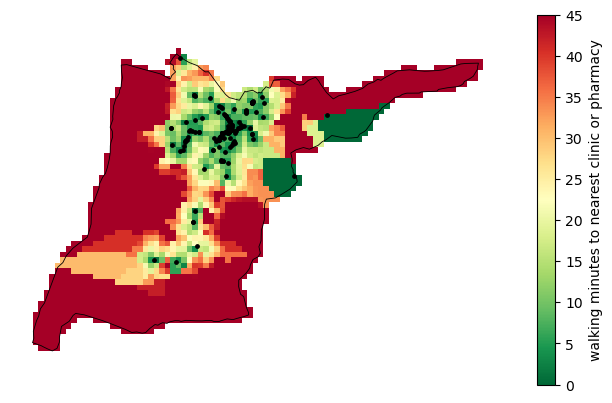

In [41]:
ax = grid.plot("min_to_clinic", cmap="RdYlGn_r", vmax=45, legend=True, figsize=(8, 8), legend_kwds={"label": "walking minutes to nearest clinic or pharmacy", "shrink": .6})
health.to_crs(CRS).plot(ax=ax, color="black", markersize=6); area.boundary.plot(ax=ax, color="k", lw=.6); ax.set_axis_off();

## 6. Kernel density: where do shops concentrate?
Kernel density smooths points into a surface: each shop spreads a little bump of 300 m; bumps add up.

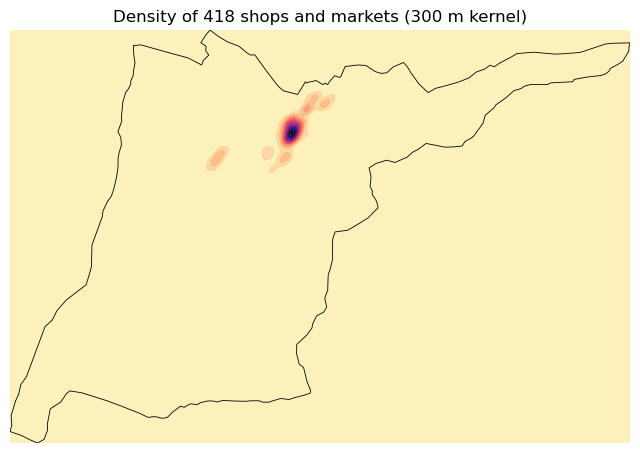

In [42]:
from scipy.stats import gaussian_kde
shops = poi[poi.category == "shops and markets"]
xy = np.vstack([shops.geometry.x, shops.geometry.y])
kde = gaussian_kde(xy, bw_method=300 / xy.std(axis=1).mean())
gx, gy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
z = kde(np.vstack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(8, 8))
ax.contourf(gx, gy, z, levels=15, cmap="magma_r", alpha=.85); area.boundary.plot(ax=ax, color="k", lw=.6)
ax.set_title(f"Density of {len(shops)} shops and markets (300 m kernel)"); ax.set_axis_off();

## 7. Is it clustered more than chance? Moran's I and hot spots
*Moran's I* asks whether neighbouring cells have similar values (I > 0: clustering). *Getis-Ord Gi\** marks cells
whose neighbourhood is much higher (hot) or lower (cold) than the city overall.

Moran's I = 0.45, pseudo p = 0.001


hotspot
not significant    1870
hot                  20
Name: count, dtype: int64

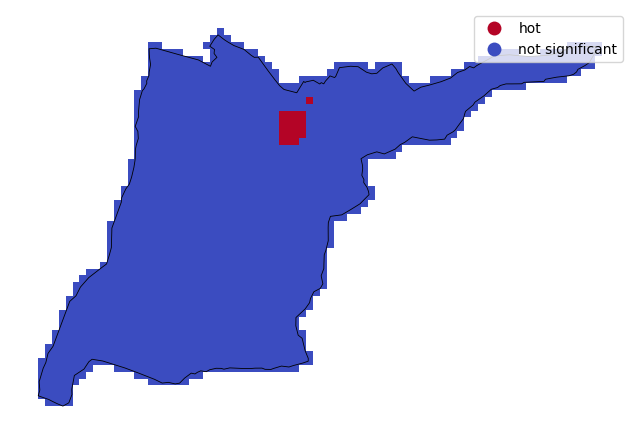

In [43]:
from libpysal.weights import Queen
from esda.moran import Moran
from esda.getisord import G_Local
grid["shops"] = gpd.sjoin(shops[["geometry"]], grid, predicate="within").groupby("cell").size().reindex(grid.cell).fillna(0).values
w = Queen.from_dataframe(grid, use_index=False); w.transform = "r"
mi = Moran(grid.shops.values, w, permutations=999)
print(f"Moran's I = {mi.I:.2f}, pseudo p = {mi.p_sim:.3f}")
gl = G_Local(grid.shops.values.astype(float), w, star=True, permutations=999, seed=0)
grid["hotspot"] = np.select([(gl.Zs > 1.96) & (gl.p_sim < .05), (gl.Zs < -1.96) & (gl.p_sim < .05)], ["hot", "cold"], "not significant")
ax = grid.plot("hotspot", categorical=True, cmap="coolwarm_r", legend=True, figsize=(8, 8)); area.boundary.plot(ax=ax, color="k", lw=.6); ax.set_axis_off()
grid.hotspot.value_counts()

## 8. Save the results for maps and questions

In [44]:
grid.to_file(DATA / "grid_500m.gpkg")
grid[["buildings", "built_share", "people", "min_to_clinic", "shops"]].describe().round(2)

,buildings,built_share,people,min_to_clinic,shops
count,1890.00,1890.00,1890.00,1890.00,1890.00
mean,134.42,0.07,342.25,58.43,0.22
std,228.42,0.11,511.32,40.62,1.89
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,24.28,0.00
50%,1.50,0.00,0.00,52.99,0.00
75%,192.75,0.10,797.70,96.18,0.00
max,1174.00,0.70,1973.04,185.40,46.00


## Caveats to state in any write-up
- Results depend on the grid (try 250 m and 1 km): the *modifiable areal unit problem*.
- Missing OSM data look like poor access. Check tags, coverage and local knowledge before claiming a gap.
- Walking times ignore slope, safety, gates, traffic and who is allowed where. Notebook 06 shows how to bring
  these in for particular groups.

[Back to contents](#contents). Next: [Chapter 6. Making maps and graphics that tell the truth, and making them interactive](#chapter-05).

# <a id="chapter-05"></a>Chapter 6. Making maps and graphics that tell the truth, and making them interactive

A map is an argument. This notebook shows the choices that change what a reader sees (classes, colours,
normalisation), then several kinds of map and chart, then interactivity inside the notebook:

| Tool | Use | Works when shared |
|---|---|---|
| matplotlib / geopandas `.plot()` | print-quality static maps and figures | always (image) |
| geopandas `.explore()` / **folium** | zoomable web maps with hover, layers, heat maps, side-by-side | yes (HTML saved in the notebook) |
| **plotly** | interactive charts: hover, zoom, filter by legend | yes |
| **ipywidgets** | sliders and menus that re-run code | only in a live notebook (Jupyter, Colab, VS Code) |

In [45]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt, mapclassify as mc
DATA, CRS = Path("data"), 32642
grid = gpd.read_file(DATA / "grid_500m.gpkg")
area = gpd.read_file(DATA / "boundary.gpkg").to_crs(CRS)
poi = gpd.read_file(DATA / "places.gpkg").to_crs(CRS)
lived = grid[grid.people > 50].copy()
lived["people_per_ha"] = lived.people / 25

## 1. Same data, four maps: class schemes change the story

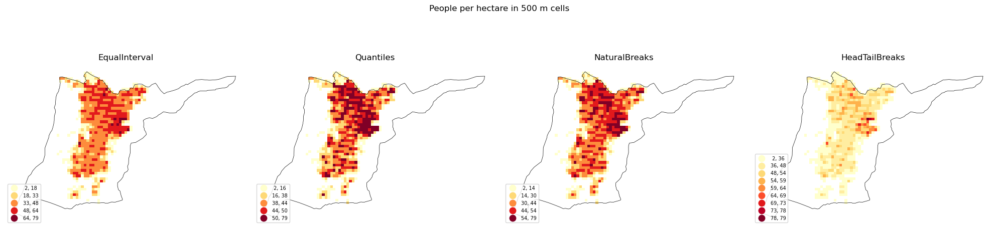

In [46]:
fig, ax = plt.subplots(1, 4, figsize=(20, 5.5))
for a, s in zip(ax, ["EqualInterval", "Quantiles", "NaturalBreaks", "HeadTailBreaks"]):
    lived.plot("people_per_ha", scheme=s, k=5, cmap="YlOrRd", ax=a, legend=True, legend_kwds={"loc": "lower left", "fontsize": 7, "fmt": "{:.0f}"})
    area.boundary.plot(ax=a, color="k", lw=.5); a.set_title(s); a.set_axis_off()
plt.suptitle("People per hectare in 500 m cells"); plt.tight_layout()

Equal intervals hide variation among most cells; quantiles exaggerate small differences; natural breaks follow
gaps; head/tail breaks suit very skewed data (a few very dense cells). Say which you used, and why.

## 2. Counts or rates? Normalise
A map of *number of clinics* shows where cells are big or busy; *clinics per 10,000 people* shows provision.

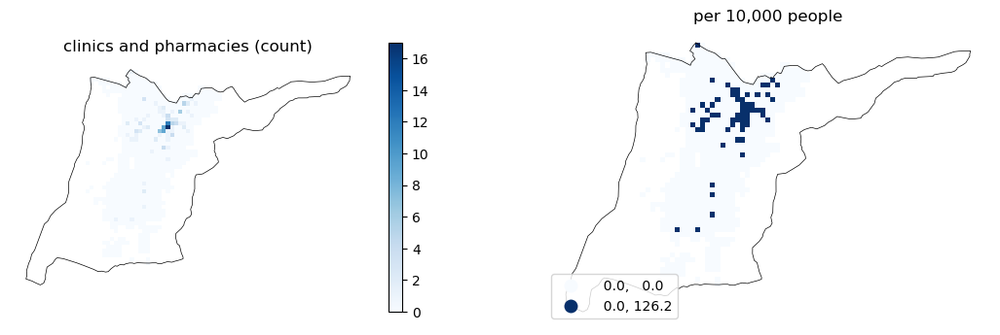

In [47]:
lived["clinics"] = gpd.sjoin(poi[poi.category == "health"][["geometry"]], lived, predicate="within").groupby("cell").size().reindex(lived.cell).fillna(0).values
lived["clinics_per_10k"] = lived.clinics / lived.people * 1e4
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
lived.plot("clinics", ax=ax[0], cmap="Blues", legend=True, legend_kwds={"shrink": .6}); ax[0].set_title("clinics and pharmacies (count)")
lived.plot("clinics_per_10k", ax=ax[1], cmap="Blues", scheme="Quantiles", k=5, legend=True, legend_kwds={"loc": "lower left", "fmt": "{:.1f}"}); ax[1].set_title("per 10,000 people")
for a in ax: area.boundary.plot(ax=a, color="k", lw=.5); a.set_axis_off()

## 3. Two variables on one map: a bivariate choropleth
Population density against walking time to a clinic: dense *and* far is where need meets distance.

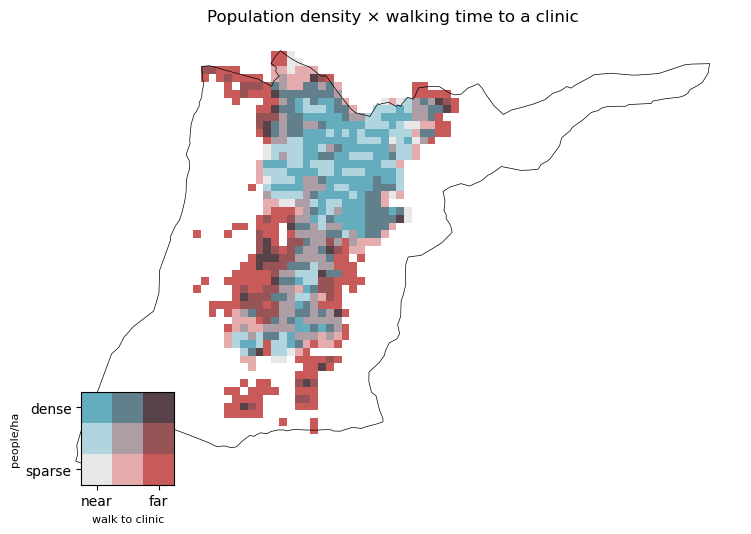

In [48]:
q = lambda s: pd.qcut(s.rank(method="first"), 3, labels=False)
lived["bv"] = q(lived.people_per_ha).astype(int) * 3 + q(lived.min_to_clinic.fillna(lived.min_to_clinic.max())).astype(int)
pal = ["#e8e8e8", "#e4acac", "#c85a5a", "#b0d5df", "#ad9ea5", "#985356", "#64acbe", "#627f8c", "#574249"]
fig, ax = plt.subplots(figsize=(9, 9))
lived.plot(color=[pal[i] for i in lived.bv], ax=ax); area.boundary.plot(ax=ax, color="k", lw=.5); ax.set_axis_off()
ins = ax.inset_axes([.02, .02, .2, .2])
ins.imshow(np.array([[int(pal[r * 3 + c][1:], 16) for c in range(3)] for r in range(3)])[::-1].astype(np.uint32).view(np.uint8).reshape(3, 3, 4)[:, :, 2::-1], origin="upper")
ins.set_xticks([0, 2], ["near", "far"]); ins.set_yticks([0, 2], ["dense", "sparse"]); ins.set_xlabel("walk to clinic", fontsize=8); ins.set_ylabel("people/ha", fontsize=8)
ax.set_title("Population density × walking time to a clinic");

## 4. Small multiples: one map per category

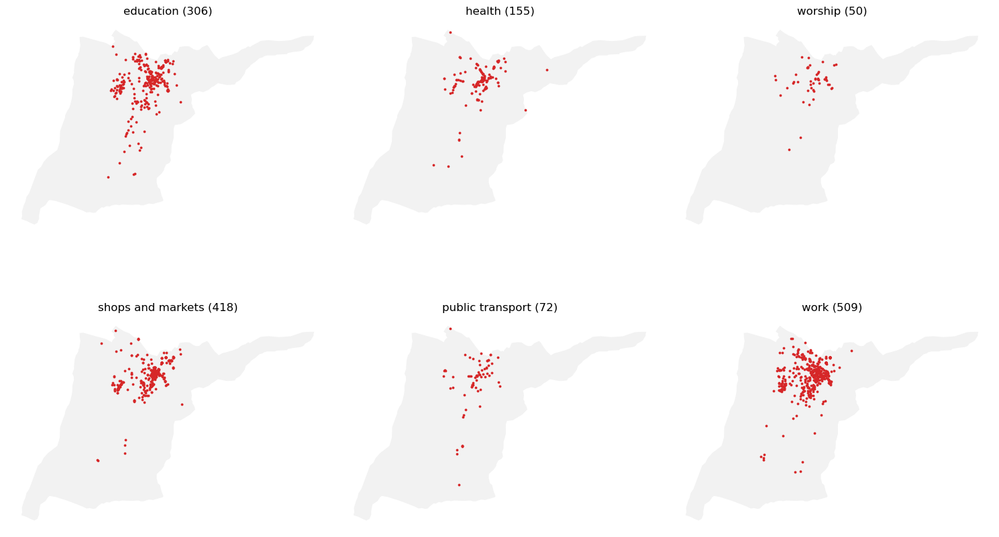

In [49]:
cats = ["education", "health", "worship", "shops and markets", "public transport", "work"]
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for a, c in zip(ax.ravel(), cats):
    area.plot(ax=a, color="#f2f2f2"); sub = poi[poi.category == c]
    sub.plot(ax=a, markersize=3, color="C3"); a.set_title(f"{c} ({len(sub)})"); a.set_axis_off()
plt.tight_layout()

## 5. Charts that go with maps

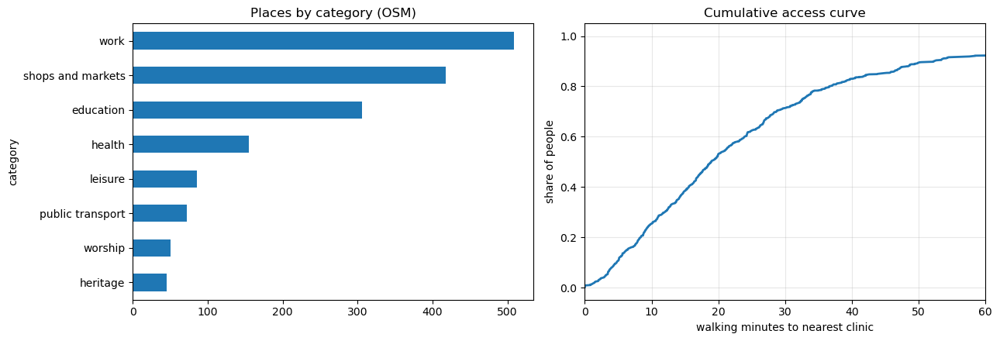

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
poi.category.value_counts().plot.barh(ax=ax[0], color="C0"); ax[0].set_title("Places by category (OSM)"); ax[0].invert_yaxis()
w = lived.dropna(subset=["min_to_clinic"]).sort_values("min_to_clinic")
ax[1].plot(w.min_to_clinic, w.people.cumsum() / w.people.sum(), lw=2)
ax[1].set(xlabel="walking minutes to nearest clinic", ylabel="share of people", title="Cumulative access curve", xlim=(0, 60)); ax[1].grid(alpha=.3)
plt.tight_layout()

## 6. Interactive maps in the notebook
### One line: `explore()`

In [51]:
lived.to_crs(4326).explore(column="min_to_clinic", cmap="RdYlGn_r", scheme="Quantiles", k=5,
                           tooltip=["people", "buildings", "min_to_clinic", "shops"], tiles="Esri.WorldGrayCanvas",
                           style_kwds={"weight": 0, "fillOpacity": .6}, legend_kwds={"caption": "walk to clinic (min)"})

### Several layers, a heat map and a minimap with folium

In [52]:
import folium
from folium.plugins import HeatMap, MiniMap, Fullscreen, MeasureControl
m = folium.Map(location=[30.19, 67.01], zoom_start=12, tiles="Esri.WorldGrayCanvas")
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}", attr="Esri World Imagery", name="satellite").add_to(m)
lived.to_crs(4326).explore(m=m, column="people_per_ha", cmap="YlOrRd", scheme="Quantiles", k=5, name="people per hectare", style_kwds={"weight": 0, "fillOpacity": .5})
p4 = poi.to_crs(4326)
HeatMap(list(zip(p4[p4.category == "shops and markets"].geometry.y, p4[p4.category == "shops and markets"].geometry.x)), name="shops (heat map)", radius=10, show=False).add_to(m)
p4[p4.category == "worship"].explore(m=m, color="green", name="places of worship", marker_kwds={"radius": 3}, tooltip=["name"] if "name" in p4 else None)
MiniMap().add_to(m); Fullscreen().add_to(m); MeasureControl().add_to(m)
folium.LayerControl(collapsed=False).add_to(m); m

### Side by side: two maps that pan and zoom together

In [53]:
from folium.plugins import DualMap
dm = DualMap(location=[30.19, 67.01], zoom_start=13, tiles=None)
folium.TileLayer("Esri.WorldGrayCanvas").add_to(dm.m1)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}", attr="Esri World Imagery").add_to(dm.m2)
lived.to_crs(4326).explore(m=dm.m1, column="buildings", cmap="viridis", style_kwds={"weight": 0, "fillOpacity": .6}, legend=False)
dm

Left: buildings per cell from the data. Right: satellite imagery. Pan either: does the data match what you see?

### Interactive charts with plotly

In [54]:
import plotly.express as px
px.scatter(lived, x="people_per_ha", y="min_to_clinic", size="buildings", color="shops", hover_data=["cell"],
           labels={"people_per_ha": "people per hectare", "min_to_clinic": "walk to clinic (min)"},
           title="Each 500 m cell: density, access, shops (hover a bubble)", height=480)

### Sliders and menus (live notebooks only)
`ipywidgets` re-runs a function when a control moves. In a published page the slider does nothing, because no
Python is running behind it; open the notebook in Colab or Jupyter to use it.

```python
import ipywidgets as w
@w.interact(minutes=w.IntSlider(5, 5, 60, 5))
def show(minutes=15):
    ax = lived.plot(color="#eee", figsize=(6, 6))
    lived[lived.min_to_clinic <= minutes].plot(ax=ax, color="C2")
    ax.set_title(f"{lived.people[lived.min_to_clinic <= minutes].sum() / lived.people.sum():.0%} of people within {minutes} min"); ax.set_axis_off()
```

## Saving and sharing
- Static: `plt.savefig("map.png", dpi=300)`; for print use PDF or SVG.
- Interactive: `m.save("map.html")` gives one file anyone can open in a browser; plotly: `fig.write_html(...)`.
- Always add the data credit: "© OpenStreetMap contributors (ODbL); Overture Maps; WorldPop (CC BY 4.0)".

[Back to contents](#contents). Next: [Chapter 7. Asking your discipline's questions of a place](#chapter-06).

# <a id="chapter-06"></a>Chapter 7. Asking your discipline's questions of a place

The same layers answer very different questions. Each section below starts from a question a researcher in one
field might ask about Quetta, turns it into a query, and says what the answer can and cannot support. They are
starting points for fieldwork and archives, not substitutes for them.

| Field | Question |
|---|---|
| Sociology | Are schools and clinics shared evenly among the city's people? |
| Gender studies | Which bus stops can be reached along busy, shop-lined streets, and how many live near them? |
| Labour studies | Where is paid work, and how far is it from where people live? |
| Anthropology, religion | How are places of worship spread, and what share of people live within earshot of one? |
| History | What do street and place names remember? |
| Literature | Mapping the places named in a text |
| Urban studies | Which parts of the city are dense, built-up and poorly served? |
| Political geography | Where are extraction, roads and violence, and who lives near them? (province) |

In [55]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, osmnx as ox, matplotlib.pyplot as plt
DATA, CRS = Path("data"), 32642
area = gpd.read_file(DATA / "boundary.gpkg").to_crs(CRS)
grid = gpd.read_file(DATA / "grid_500m.gpkg")
poi = gpd.read_file(DATA / "places.gpkg").to_crs(CRS)
edges = ox.graph_to_gdfs(ox.load_graphml(DATA / "walk.graphml"), nodes=False).to_crs(CRS)
lived = grid[grid.people > 50].copy()

## Sociology: are services shared evenly?
A *concentration curve* sorts cells from best to worst served and plots the share of people against the share of
services. The *Gini coefficient* summarises it: 0 = perfectly even, 1 = all in one place.

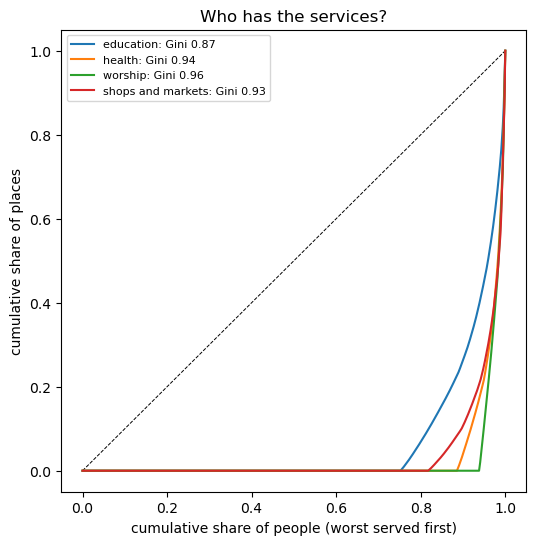

In [56]:
def gini_share(people, services):
    """Gini of services per person across cells, weighted by people."""
    o = np.argsort(services / np.maximum(people, 1))
    p, s = np.cumsum(people[o]) / people.sum(), np.cumsum(services[o]) / max(services.sum(), 1)
    return 1 - 2 * np.trapezoid(s, p), p, s
fig, ax = plt.subplots(figsize=(6, 6)); ax.plot([0, 1], [0, 1], "k--", lw=.7)
for cat in ["education", "health", "worship", "shops and markets"]:
    n = gpd.sjoin(poi[poi.category == cat][["geometry"]], lived, predicate="within").groupby("cell").size().reindex(lived.cell).fillna(0).values
    g, p, s = gini_share(lived.people.values, n)
    ax.plot(np.r_[0, p], np.r_[0, s], label=f"{cat}: Gini {g:.2f}")
ax.set(xlabel="cumulative share of people (worst served first)", ylabel="cumulative share of places", title="Who has the services?"); ax.legend(fontsize=8);

**Can support:** a description of spatial inequality in *mapped* services. **Cannot:** quality, cost, who is
admitted, or services missing from OSM (private tutors, informal clinics). Pair with household surveys.

## Gender studies: reachable public transport along "active" streets
Many studies of women's mobility find that busy, shop-lined, well-lit streets feel safer than empty ones. Here an
*active street* is a segment with at least 3 shops within 50 m. Which bus stops are on active streets, and how many
people live within 400 m of one? (Better data on lighting, harassment reports or walk-along interviews would
change the definition; the method stays the same.)

In [57]:
shops = poi[poi.category == "shops and markets"]
e = edges[["geometry"]].reset_index(drop=True)
e["shops_50m"] = gpd.sjoin(shops[["geometry"]], e.assign(geometry=e.buffer(50)), predicate="within").groupby("index_right").size().reindex(e.index).fillna(0).values
e["active"] = e.shops_50m >= 3
stops = poi[poi.category == "public transport"]
near = gpd.sjoin_nearest(stops[["geometry"]], e[["active", "geometry"]], max_distance=30, how="left")
active_stops = stops.loc[near[near.active.fillna(False).astype(bool)].index.unique()]
print(f"{e.active.mean():.0%} of street segments are 'active'; {len(active_stops)} of {len(stops)} mapped stops lie on one")
c = lived.copy(); c["geometry"] = lived.centroid
for name, s in [("any stop", stops), ("a stop on an active street", active_stops)]:
    within = c.within(s.buffer(400).union_all()) if len(s) else pd.Series(False, index=c.index)
    print(f"people within 400 m of {name}: {lived.people[within.values].sum() / lived.people.sum():.0%}")

1% of street segments are 'active'; 6 of 72 mapped stops lie on one
people within 400 m of any stop: 16%
people within 400 m of a stop on an active street: 2%


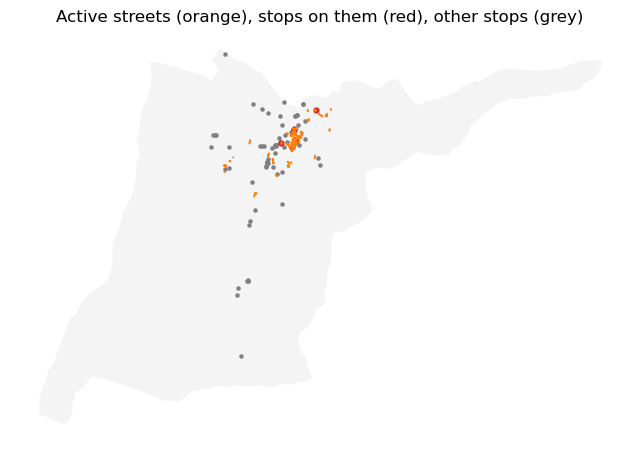

In [58]:
ax = area.plot(color="#f4f4f4", figsize=(8, 8))
e[e.active].plot(ax=ax, color="C1", lw=1.2, label="active street"); stops.plot(ax=ax, color="grey", markersize=5)
active_stops.plot(ax=ax, color="C3", markersize=12); ax.set_axis_off(); ax.set_title("Active streets (orange), stops on them (red), other stops (grey)");

**Reading:** only about 1% of street segments have 3 or more mapped shops within 50 m, and 6 of 72 mapped stops
lie on such a street: 16% of people live within 400 m of any mapped stop, 2% of one on an active street.
Bus stops in Quetta are sparsely mapped (most transport is informal: rickshaws, vans, *chingchi*). A low number
here is a finding about the *map*, which is itself worth reporting.

## Labour studies: where is work, and how far from home?
Workplaces in OSM: industrial land, works, offices, markets. Distance from each populated cell to the nearest
workplace, weighted by people:

In [59]:
work = poi[poi.category.isin(["work", "shops and markets"])]
d = gpd.sjoin_nearest(c[["cell", "people", "geometry"]], work[["geometry"]], distance_col="m").drop_duplicates("cell")
wq = np.average(d.m, weights=d.people)
print(f"people-weighted mean straight-line distance to the nearest mapped workplace: {wq:,.0f} m")
print(d.assign(km=pd.cut(d.m, [0, 250, 500, 1000, 2000, 1e9], labels=["<250 m", "250-500", "0.5-1 km", "1-2 km", ">2 km"])).groupby("km").people.sum().div(d.people.sum()).round(2))

people-weighted mean straight-line distance to the nearest mapped workplace: 700 m
km
<250 m      0.28
250-500     0.22
0.5-1 km    0.25
1-2 km      0.21
>2 km       0.04
Name: people, dtype: float32


**Next steps a labour researcher might take:** add brick kilns, coal-mine access roads and labour *addas* (daily
wage pick-up points) from fieldwork; compare with census occupation tables; map commuting routes from interviews.

## Anthropology and religion: places of worship and earshot
A call to prayer carries several hundred metres. What share of people live within 300 m of a mapped mosque,
church, temple or gurdwara? `religion` tags (where present) show diversity.

In [60]:
w = poi[poi.category == "worship"]
print(w.get("religion", pd.Series(dtype=str)).fillna("not tagged").value_counts().head(6))
print(f"people within 300 m of a mapped place of worship: {lived.people[c.within(w.buffer(300).union_all()).values].sum() / lived.people.sum():.0%}")

religion
muslim        24
not tagged    23
hindu          2
christian      1
Name: count, dtype: int64
people within 300 m of a mapped place of worship: 7%


**Reading:** only about 50 places of worship are mapped, and about 7% of people live within 300 m of one. Quetta
has hundreds of mosques, plus churches, temples and imambargahs, so the number shows how little of the city's
religious life is on the open map, not how far people live from it. A researcher would map them in the field (an
OSM mapping day is a good research method) before measuring anything.

## History: what do names remember?
Street and place names record rulers, saints, tribes, colonial officers and events. Grouping names by their words
is a first step; OSM's `name:etymology:wikidata` tag (where mappers added it) links a name to the person it honours.

In [61]:
names = pd.Series(edges["name"].dropna().astype(str).unique()) if "name" in edges else pd.Series(dtype=str)
names = names.str.replace(r"[\[\]']", "", regex=True)
words = names.str.split(r"[\s,]+").explode().str.strip()
words = words[words.str.len() > 2]
common = words[~words.str.lower().isin(["road", "street", "the", "and", "bazar", "bazaar", "lane", "chowk"])].value_counts().head(20)
print(len(names), "named streets"); common

355 named streets


روڈ         32
Colony      18
Town        14
Area        14
Muhammad    14
Khan        13
No.         11
Sariab       8
Killi        8
Ismail       7
Haji         7
Ali          6
Kasi         5
Malik        5
Abdul        5
Stop         5
Din          5
Mengal       5
شاہراہ       5
Mir          5
Name: count, dtype: int64

Colonial names (e.g. after British officers), Baloch, Pashtun and Hazara names, and post-1947 renamings sit side by
side. A historian would continue with gazetteers, colonial-era maps (for example the 1890s Survey of India sheets)
overlaid as a layer in `folium` (`folium.raster_layers.ImageOverlay` for a georeferenced scan).

## Literature: mapping the places named in a text
Geocode place names from a novel, memoir or poem, then map them. The list below is illustrative; replace it with
names extracted from your text (by hand or with a named-entity tagger).

In [62]:
text_places = ["Quetta Railway Station", "Liaquat Bazar", "Hanna Lake", "Jinnah Road", "Quetta Cantonment", "Mari Abad"]
rows = []
for p in text_places:
    try:
        g = ox.geocode(f"{p}, Quetta, Pakistan"); rows.append({"place": p, "lat": g[0], "lon": g[1]})
    except Exception:
        rows.append({"place": p, "lat": np.nan, "lon": np.nan})
tp = pd.DataFrame(rows); print(tp)
tp = tp.dropna()
if len(tp):
    m = gpd.GeoDataFrame(tp, geometry=gpd.points_from_xy(tp.lon, tp.lat), crs=4326).explore(marker_kwds={"radius": 7}, color="crimson", tooltip=["place"], tiles="Esri.WorldGrayCanvas")
    import folium
    folium.PolyLine(list(zip(tp.lat, tp.lon)), color="crimson", weight=2, dash_array="5").add_to(m)
m if len(tp) else "no places found"

                    place        lat        lon
0  Quetta Railway Station  30.191627  67.000756
1           Liaquat Bazar  30.191704  67.014432
2              Hanna Lake  30.255951  67.099677
3             Jinnah Road  30.197344  67.012121
4       Quetta Cantonment  30.226697  67.045621
5               Mari Abad        NaN        NaN


Order the places as they appear in the text to draw a character's route; colour them by chapter; add quotations
as pop-ups. Places that cannot be geocoded are part of the reading: invented, renamed or lost.

## Urban studies: dense, built-up and poorly served

In [63]:
lived["flag"] = (lived.people >= lived.people.quantile(.75)) & (lived.min_to_clinic >= 15)
print(f"{lived.flag.sum()} cells are in the densest quarter and >= 15 min walk from a clinic, home to {lived.people[lived.flag].sum():,.0f} people")
lived.to_crs(4326).explore(column="flag", cmap=["#dddddd", "#c0392b"], tooltip=["people", "min_to_clinic", "buildings"], tiles="Esri.WorldGrayCanvas", style_kwds={"weight": 0, "fillOpacity": .6})

88 cells are in the densest quarter and >= 15 min walk from a clinic, home to 121,516 people


## Political geography: the province (data from notebook 02)
Three questions often asked about Balochistan, each as a query. They describe patterns; explaining them needs
history, interviews and documents.

**Where is extraction, and who lives there?** Mapped mines, quarries, wells and works per district against
population and urban share.

In [64]:
dist = gpd.read_file(DATA / "bal_districts.gpkg").to_crs(CRS)
ext = gpd.read_file(DATA / "bal_extraction.gpkg").to_crs(CRS)
roads = gpd.read_file(DATA / "bal_roads.gpkg").to_crs(CRS)
dist["extraction_sites"] = gpd.sjoin(ext, dist[["adm2_name", "geometry"]], predicate="within").groupby("adm2_name").size().reindex(dist.adm2_name).fillna(0).values
dist[["adm2_name", "extraction_sites", "pop2017", "urban_share", "events"]].sort_values("extraction_sites", ascending=False).head(10).round(2)

,adm2_name,extraction_sites,pop2017,urban_share,events
16,Lasbela,93.0,574292.0,0.49,12.0
8,Kachhi,23.0,237030.0,0.15,26.0
12,Khuzdar,21.0,802207.0,0.35,39.0
3,Dera Bugti,19.0,312603.0,0.32,88.0
4,Gwadar,18.0,263514.0,0.61,59.0
2,Chagai,17.0,226008.0,0.07,14.0
21,Nasirabad,16.0,490538.0,0.20,21.0
14,Killa Saifullah,13.0,342814.0,0.18,4.0
24,Pishin,12.0,736481.0,0.19,14.0
25,Quetta,9.0,2275699.0,0.44,210.0


**How far are people from a main road?** A proxy for distance from markets, services and the state, and also from
checkpoints. Population-weighted distance from each district's towns and villages to the nearest trunk or primary
road:

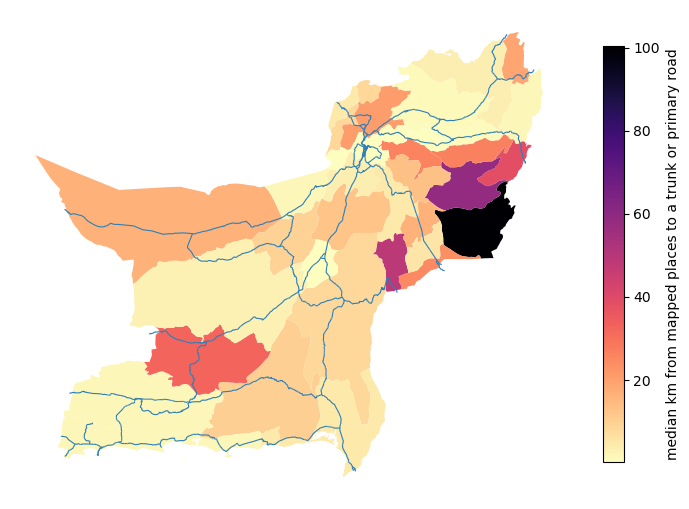

In [65]:
pl = gpd.read_file(DATA / "bal_places.gpkg").to_crs(CRS)
main = roads[roads.highway.isin(["motorway", "trunk", "primary"])]
pl = gpd.sjoin_nearest(pl, main[["geometry"]], distance_col="km").drop_duplicates(subset="geometry")
pl["km"] /= 1000
pl = gpd.sjoin(pl.drop(columns="index_right"), dist[["adm2_name", "geometry"]], predicate="within")
r = pl.groupby("adm2_name").km.agg(["size", "median"]).rename(columns={"size": "mapped places", "median": "median km to main road"})
dist = dist.merge(r, left_on="adm2_name", right_index=True, how="left")
ax = dist.plot("median km to main road", cmap="magma_r", legend=True, figsize=(9, 9), missing_kwds={"color": "#ddd"}, legend_kwds={"label": "median km from mapped places to a trunk or primary road", "shrink": .6})
main.plot(ax=ax, color="#2c7fb8", lw=.8); ax.set_axis_off();

**Is violence near the roads and the extraction sites?** Share of located UCDP events within 5 km of a main road or
10 km of a mapped extraction site, against the share of the province's area within those distances. A share of
events much higher than the share of area means events concentrate there.

In [66]:
ev = gpd.read_file(DATA / "bal_events.gpkg").to_crs(CRS)
ev = ev[ev.where_prec <= 3]
prov = dist.union_all()
for label, zone in [("within 5 km of a main road", main.buffer(5000).union_all()), ("within 10 km of a mapped extraction site", ext.buffer(10000).union_all())]:
    z = zone.intersection(prov)
    print(f"{label}: {ev.within(z).mean():.0%} of events, {z.area / prov.area:.0%} of the province's area")

within 5 km of a main road: 55% of events, 15% of the province's area
within 10 km of a mapped extraction site: 34% of events, 6% of the province's area


**Reading:** 55% of located events lie within 5 km of a main road, which covers 15% of the province; 34% lie
within 10 km of a mapped extraction site, 6% of its area. Lasbela (industrial estates near Karachi) has by far the
most mapped extraction sites; Dera Bugti (gas) and Gwadar (port) combine many sites with many events.
Events are reported where reporters, roads and towns are, so closeness to roads is partly a reporting effect. This
is the kind of result to discuss with people who know the places before writing it up.

## Turning a question into a query: a recipe
1. **Name the thing** you care about (safety, access, belonging, memory, work).
2. **Find a proxy** in the data, and write down what it misses.
3. **Choose the unit** (building, street, cell, neighbourhood) and the distance (straight, walking, time).
4. **Compute, map, compare** with another place or group.
5. **Check against the ground**: interviews, archives, photographs, field visits.
6. **Report the limits** with the result.

**Credits:** © OpenStreetMap contributors (ODbL); Overture Maps Foundation (CDLA-Permissive 2.0 / ODbL);
WorldPop 2020 (CC BY 4.0).

[Back to contents](#contents). Next: [Chapter 8. Ethics, safety and critical cartography](#chapter-07).

# <a id="chapter-07"></a>Chapter 8. Ethics, safety and critical cartography

A map of people in a contested place can protect them or endanger them. Balochistan has a long record of armed
conflict, enforced disappearances, surveillance and restrictions on journalists and researchers. Treat every
location of a person, home, meeting or event involving identifiable people as sensitive data.

## A checklist before you collect, map or share

| Stage | Ask | Do |
|---|---|---|
| Plan | Who could use this map, and against whom? | Write a short data-protection plan; discuss it with your ethics board and with participants |
| Consent | Did people agree to be *mapped*, not only interviewed? At what precision? | Record the precision each person agreed to |
| Collect | Does my phone add locations to photos and notes? | Turn off location tagging; strip EXIF metadata (below); use pseudonyms from the start |
| Store | Who can open my files if my phone or laptop is taken? | Encrypt (VeraCrypt, BitLocker, FileVault); keep field data offline; separate the key linking pseudonyms to names |
| Analyse | Do I need exact points? | Work with areas, grids or jittered points; keep exact data off cloud services, including Colab |
| Publish | Could a reader find a person or home from this map? | Aggregate (district, grid), suppress small counts, coarsen, delay; never publish home locations of participants |
| Share code | Does the notebook contain real data, keys or names? | Share code with made-up data; keep keys in environment variables |

## Strip the hidden location from a photograph

In [67]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from PIL import Image
DATA, CRS = Path("data"), 32642
img = Image.new("RGB", (60, 40), "grey"); exif = img.getexif(); exif[0x8825] = {2: (30.0, 11.0, 0.0), 4: (67.0, 1.0, 0.0)}
img.save(DATA / "photo_with_gps.jpg", exif=exif)                          # a test photo carrying a GPS position

def strip_metadata(src, dst):
    """Save a copy of an image without any EXIF metadata (GPS position, camera, time)."""
    im = Image.open(src); clean = Image.new(im.mode, im.size); clean.putdata(list(im.getdata())); clean.save(dst)
strip_metadata(DATA / "photo_with_gps.jpg", DATA / "photo_clean.jpg")
for f in ["photo_with_gps.jpg", "photo_clean.jpg"]:
    print(f, "-> GPS present:", 0x8825 in Image.open(DATA / f).getexif())

photo_with_gps.jpg -> GPS present: True
photo_clean.jpg -> GPS present: False


## Protecting locations: three techniques, side by side
Made-up "participant homes" in Quetta, shown exact, jittered, snapped to a grid and aggregated with small counts
suppressed.

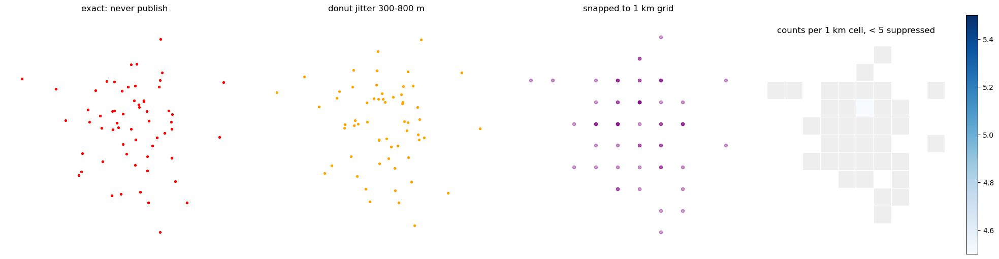

In [68]:
rng = np.random.default_rng(1)
homes = gpd.GeoDataFrame(geometry=gpd.points_from_xy(67.0 + rng.normal(0, .02, 60), 30.19 + rng.normal(0, .02, 60)), crs=4326).to_crs(CRS)
jit = homes.copy(); ang, r = rng.uniform(0, 2 * np.pi, len(jit)), rng.uniform(300, 800, len(jit))
jit["geometry"] = gpd.points_from_xy(jit.geometry.x + r * np.cos(ang), jit.geometry.y + r * np.sin(ang))   # donut jitter: at least 300 m away
S = 1000
snap = homes.copy(); snap["geometry"] = gpd.points_from_xy((homes.geometry.x // S + .5) * S, (homes.geometry.y // S + .5) * S)
cnt = snap.groupby([snap.geometry.x, snap.geometry.y]).size().rename("n").reset_index()
from shapely.geometry import box
cells = gpd.GeoDataFrame(cnt, geometry=[box(x - S / 2, y - S / 2, x + S / 2, y + S / 2) for x, y in zip(cnt.iloc[:, 0], cnt.iloc[:, 1])], crs=CRS)
cells["shown"] = np.where(cells.n >= 5, cells.n, np.nan)                    # suppress cells with fewer than 5
fig, ax = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
homes.plot(ax=ax[0], color="red", markersize=8); ax[0].set_title("exact: never publish")
jit.plot(ax=ax[1], color="orange", markersize=8); ax[1].set_title("donut jitter 300-800 m")
snap.plot(ax=ax[2], color="purple", markersize=20, alpha=.4); ax[2].set_title("snapped to 1 km grid")
cells.plot(ax=ax[3], column="shown", cmap="Blues", legend=True, missing_kwds={"color": "#eee", "label": "< 5 hidden"}, edgecolor="white")
ax[3].set_title("counts per 1 km cell, < 5 suppressed")
for a in ax: a.set_axis_off()
plt.tight_layout()

Jitter alone can be undone if the same people are published twice with different jitter, or if few buildings lie
nearby: prefer aggregation for anything public, and keep the exact data encrypted and offline.

## Critical cartography: the same data, different claims
**Borders.** Pakistan's border with Afghanistan (the Durand Line) is not recognised by Afghanistan; parts of
Balochistan's history (the Khanate of Kalat, its accession in 1948) are contested. A boundary file encodes one
government's view. Say whose boundaries you use (here: OCHA/HDX, following Pakistan's official lines) and consider
showing contested lines as dashed.

**Names.** Baluchistan or Balochistan; Kalat state or Kalat district; the name an armed group is given by the state,
by UCDP, by its supporters. Choose deliberately and say why.

**Classes and colours.** Below, the same UCDP events by district: raw counts in alarming red, and rates per
population in a neutral sequential palette with stated classes. Neither is false; they make different arguments.

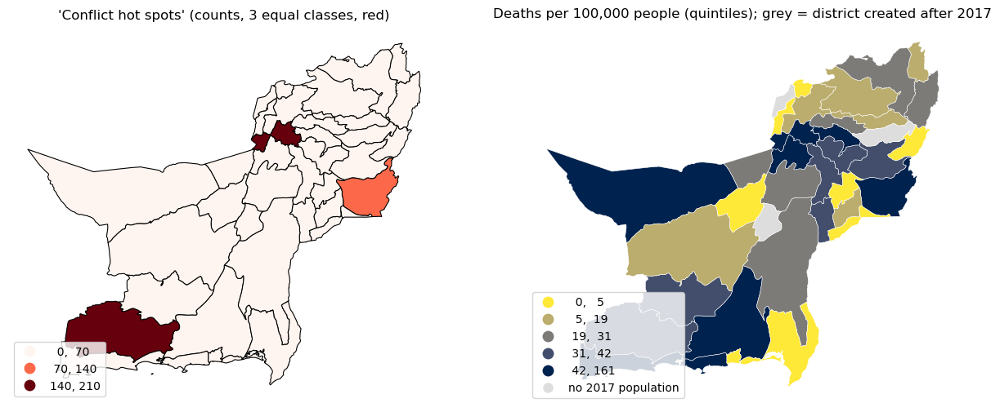

In [69]:
d = gpd.read_file(DATA / "bal_districts.gpkg")
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
d.plot("events", ax=ax[0], cmap="Reds", scheme="EqualInterval", k=3, legend=True, edgecolor="black", lw=.8, legend_kwds={"loc": "lower left", "fmt": "{:.0f}"})
ax[0].set_title("'Conflict hot spots' (counts, 3 equal classes, red)")
d.plot("deaths_per_100k", ax=ax[1], cmap="cividis_r", scheme="Quantiles", k=5, legend=True, edgecolor="white", lw=.4, missing_kwds={"color": "#ddd", "label": "no 2017 population"},
       legend_kwds={"loc": "lower left", "fmt": "{:.0f}"})
ax[1].set_title("Deaths per 100,000 people (quintiles); grey = district created after 2017")
for a in ax: a.set_axis_off()

**What is absent.** UCDP counts deaths it can verify from published sources; Balochistan is under-reported because
journalists' access is restricted. Enforced disappearances, arrests, protests and internet shutdowns, which many
residents describe as central to political life, are not in it. Sources that document them (human-rights
commissions, the Voice for Baloch Missing Persons, Amnesty International, HRCP reports) are lists and reports, not
clean datasets; mapping them requires the care above and their authors' consent.

**Who is on the open map.** In notebook 01, OpenStreetMap had 889 buildings for Quetta against Overture's 254,056,
and about 50 places of worship. Maps made from open data show the province as emptier than it is. Write this into
the caption of every map, not only the methods section.

## Further reading
- Harley, J.B. (1989) Deconstructing the map. *Cartographica* 26(2).
- Crampton, J. and Krygier, J. (2005) An introduction to critical cartography. *ACME* 4(1).
- Elwood, S. (2008) Volunteered geographic information: future research directions. *GeoJournal* 72.
- Kwan, M.-P. (2002) Feminist visualization: re-envisioning GIS as a method in feminist geographic research. *Annals of the AAG* 92(4).
- Zook, M. et al. (2017) Ten simple rules for responsible big data research. *PLoS Comput Biol* 13(3).
- Responsible Data (responsibledata.io) and the ICRC Handbook on Data Protection in Humanitarian Action (2nd ed., 2020).

[Back to contents](#contents).